# Sample exclusions and career-level imbalance

This version adds a row-level exclusion audit and repeated equal-size sensitivity analysis. **Run the single code cell.** The code remains self-contained and supports Colab; upload the workbook or supply its path. Locally, use a working notebook kernel with NumPy, pandas, NetworkX, Matplotlib, and openpyxl.

`MIN_VALID_SKILLS = 1` excludes a posting if **none** of its five skill fields contains a substantive skill. Blank values and “Not Specified” are ignored. A posting with valid skills and some unspecified slots remains eligible. Duplicate skill mentions count once. A one-skill posting contributes to prevalence and node coverage; it creates no skill-pair edge. Forcing all five slots to be populated could select more extensively coded postings. Set the minimum to 2–5 only as an explicit alternative; `minimum_skill_threshold_counts.csv` shows the resulting sample sizes.

For the supplied workbook, the exclusion ledger reconciles to 10,024 postings:

| | At least one valid skill | No valid skill | Total |
|---|---:|---:|---:|
| Known career level | 7,686 | 324 | 8,010 |
| Unspecified career level | 1,572 | 442 | 2,014 |
| Total | 9,258 | 766 | 10,024 |

The **442** rows in the lower-right cell belong to both missingness categories. They must not be subtracted twice. Career-level analyses retain **10,024 − 2,014 − 324 = 7,686** postings. Both the Skill Connectivity Matrix and this cross-level analysis use the same **7,686** postings with recorded skills and known career levels. The previous 9,258-posting connectivity results remain available as a broader-sample sensitivity comparison. An unknown career level is not imputed as Mid. All counts and exclusions are recalculated from the workbook.

## How the sensitivity check addresses imbalance

The primary analysis retains all eligible postings: Entry 737, Mid 3,033, Senior 3,755, Executive 161. These are samples of advertised demand, not a balanced training dataset. Prevalence uses each network's own posting denominator; cross-level betweenness uses its lower–higher posting-pair denominator. Such normalization does not remove sample-size effects on which skills and ties are observed, graph structure, or uncertainty.

By default, **100 repeated draws select 161 original postings from each level, without replacement within a draw**. Networks and scores are recomputed for every draw. The career-level degree–constraint check compares equally sized level networks. The cross-level check uses 161 postings on each side of every selected comparison, with the same sampled level shared across comparisons in a repetition. Full-sample outputs are retained separately. No duplicated or synthetic postings are added.

Each draw recalculates category cutoffs using the same method and equality rule as the primary analysis. The default is a separate median for each measure across skills observed in either selected level. A skill absent from a draw is marked **Not observed**, not assigned to a low category. Degree/constraint/betweenness summaries are conditional on observation and a defined measure; prevalence can be zero. Results report detection rates, classification rates, category agreement with the full-sample result, and all category frequencies. Changes can arise from both scores and cutoffs.

The 2.5th–97.5th percentile ranges describe **sensitivity to subsampling**, not population confidence intervals. With 161 postings per level, all Executive postings appear in every draw; this does not estimate Executive sampling uncertainty. Equalizing sample counts also does not equalize skill annotation completeness, industries, role composition, or selection bias. The audit reports valid-skill counts and missing-skill rates by level so these differences remain visible.

New outputs include `sample_exclusion_ledger.csv`, `sample_row_audit.csv`, `level_sample_audit.csv`, `valid_skill_count_distribution.csv`, `minimum_skill_threshold_counts.csv`, and `sample_exclusion_summary.json`. Sensitivity outputs include `balanced_skill_summary.csv`, `balanced_category_frequencies.csv`, all skill-level draws, draw diagnostics, and sampled posting row IDs. Seeds, sample sizes, and limitations are recorded in `balanced_sensitivity_metadata.json`.

The notebook uses **median cut-offs** for the primary matrix and every equal-size sensitivity draw. Mean–median comparisons and supplementary prevalence measures are exported without changing the sample, graph, or raw betweenness scores.


# Which skills connect lower- and higher-level marketing jobs?

**Run the single code cell below.** Use a working Python kernel with the required packages. All code is included; no separate Python file is needed. In Colab, upload the workbook or set its Drive path and enable the optional mount.

The output includes **complete skill-name tables for Catalyst, Accelerator, Gateway, and Niche** in each comparison. These appear before the rankings and figures. No skill names are truncated. The same lists are saved in `skill_types_summary.csv` and `skills_by_type.md`, with every skill's scores in `skill_types_detailed.csv`.

The **cross-level skill-network figure** presents Entry–Mid, Mid–Senior, and Senior–Executive with fixed skill positions. Node colors use the cross-level categories; node area increases with origin-level prevalence. Outlined nodes have the three highest cross-level scores (including ties). Its lines show skill co-occurrences within the two selected levels' postings. This is a display projection: scores are calculated on the full posting–skill graph described below, not by running ordinary betweenness on the drawn skill network.

This notebook asks a different question from the cumulative notebook: **For a specific pair of career levels, which skills lie on the shortest association paths between postings at those levels?** Entry–Mid, Mid–Senior, and Senior–Executive are analyzed separately. Each graph contains postings from only the two selected levels.

## What is connected to what?

- A **posting node** represents one advertisement, retaining its career level.
- A **skill node** represents one standardized competency.
- An edge connects a posting to each skill it requests. Every edge has length 1.

The same skill node can connect postings at both levels. Paths alternate between postings and skills. Intermediate postings from either selected level are permitted. Career level selects the path **endpoints**; paths are not assumed to be upward career journeys.

## How one posting pair contributes

Suppose a lower-level posting requests **Data Analytics and Communication**, and a higher-level posting requests **Communication and Budget Management**. Their shortest path is:

**Lower posting — Communication — Higher posting**

Communication receives 1 for this pair. If both postings instead share **two** skills, there are two equally short paths, and each shared skill receives 1/2. If no skill is shared, a longer path through other postings may connect them. An unreachable pair contributes 0.

For each skill, average these fractions over **all lower–higher posting pairs**:

$$B_{LH}(k)=\frac{1}{N_L N_H}\sum_{a\in J_L}\sum_{b\in J_H}\frac{\sigma_{ab}(k)}{\sigma_{ab}}.$$

Here, $\sigma_{ab}$ counts all shortest paths between the two postings and $\sigma_{ab}(k)$ counts those containing skill $k$. Each pair receives equal weight; pairs with more alternative paths do not receive more weight. Unreachable pairs remain in the denominator. The score lies between 0 and 1. Scores across different skills need not sum to 1 because longer paths can contain several skill nodes.

For example, a score of 0.20 means: select a lower–higher posting pair uniformly, then select one of its shortest paths uniformly; the focal skill is present with probability 0.20, treating unreachable pairs as zero. It does **not** mean that the skill produces a 20% chance of promotion.

This is **source–target restricted betweenness**, adapted with a pair-specific normalization. The implementation computes the stated formula directly and checks it against explicit posting–skill graphs. See the [NetworkX subset-betweenness definition](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.betweenness_centrality_subset.html). A compressed internal representation preserves every posting's multiplicity and the number of alternative paths; it is not ordinary skill-only betweenness.


Starting cross-level analysis. Wait for CROSS-LEVEL ANALYSIS COMPLETE.


Classification: separate medians within each comparison; equality is lower.


[1/4] Reading postings, skills, and career levels...


[2/4] Calculating Entry–Mid: lower-posting to higher-posting paths...


[2/4] Calculating Mid–Senior: lower-posting to higher-posting paths...


...

,skill_label,origin_prevalence,destination_prevalence,cross_level_betweenness,direct_shared_component,indirect_path_component,observed_in_both_levels,category
29,Social Media Marketing,0.641791,0.538081,0.333109,0.218594,0.114514,True,Catalyst
11,Data Analytics,0.392130,0.503462,0.225692,0.126384,0.099308,True,Catalyst
26,Public Relations,0.523745,0.396967,0.218600,0.129087,0.089513,True,Catalyst
6,Communication Skills,0.294437,0.253874,0.123279,0.053076,0.070202,True,Catalyst
18,Graphic Design,0.367707,0.299374,0.093317,0.054735,0.038582,True,Catalyst
21,Leadership/Team Management,0.189959,0.220574,0.091782,0.030280,0.061502,True,Catalyst
13,Digital Marketing,0.257802,0.224530,0.056634,0.029854,0.026780,True,Catalyst
9,CRM,0.094980,0.181339,0.030705,0.010257,0.020449,True,Catalyst
4,Brand Management,0.124830,0.149027,0.028230,0.010180,0.018050,True,Catalyst
28,SEO/SEM,0.093623,0.150676,0.015320,0.006522,0.008798,True,Catalyst



Mid–Senior: highest cross-level skill betweenness


,skill_label,origin_prevalence,destination_prevalence,cross_level_betweenness,direct_shared_component,indirect_path_component,observed_in_both_levels,category
45,Data Analytics,0.503462,0.601598,0.348296,0.214549,0.133747,True,Catalyst
63,Social Media Marketing,0.538081,0.350466,0.211229,0.119901,0.091328,True,Catalyst
55,Leadership/Team Management,0.220574,0.511851,0.185845,0.081593,0.104252,True,Catalyst
60,Public Relations,0.396967,0.345672,0.169760,0.089695,0.080065,True,Catalyst
40,Communication Skills,0.253874,0.174700,0.089814,0.031968,0.057846,True,Catalyst
52,Graphic Design,0.299374,0.150466,0.050585,0.024337,0.026248,True,Catalyst
47,Digital Marketing,0.224530,0.214647,0.050556,0.025913,0.024644,True,Catalyst
43,CRM,0.181339,0.184554,0.050337,0.021059,0.029278,True,Catalyst
39,Budget Management,0.078470,0.229561,0.035343,0.011583,0.023760,True,Catalyst
38,Brand Management,0.149027,0.115047,0.024221,0.009625,0.014596,True,Catalyst



Senior–Executive: highest cross-level skill betweenness


,skill_label,origin_prevalence,destination_prevalence,cross_level_betweenness,direct_shared_component,indirect_path_component,observed_in_both_levels,category
89,Leadership/Team Management,0.511851,0.838509,0.364090,0.278272,0.085818,True,Catalyst
79,Data Analytics,0.601598,0.714286,0.343844,0.264328,0.079516,True,Catalyst
94,Public Relations,0.345672,0.397516,0.121080,0.077487,0.043593,True,Catalyst
97,Social Media Marketing,0.350466,0.204969,0.070432,0.038406,0.032026,True,Catalyst
73,Budget Management,0.229561,0.347826,0.060676,0.040822,0.019854,True,Catalyst
81,Digital Marketing,0.214647,0.304348,0.046501,0.032035,0.014466,True,Catalyst
74,Communication Skills,0.174700,0.161491,0.038180,0.017060,0.021119,True,Catalyst
77,CRM,0.184554,0.186335,0.034652,0.018212,0.016439,True,Catalyst
78,Customer Engagement,0.079627,0.062112,0.018744,0.003281,0.015463,True,Catalyst
96,SEO/SEM,0.135553,0.111801,0.015412,0.007777,0.007635,True,Catalyst


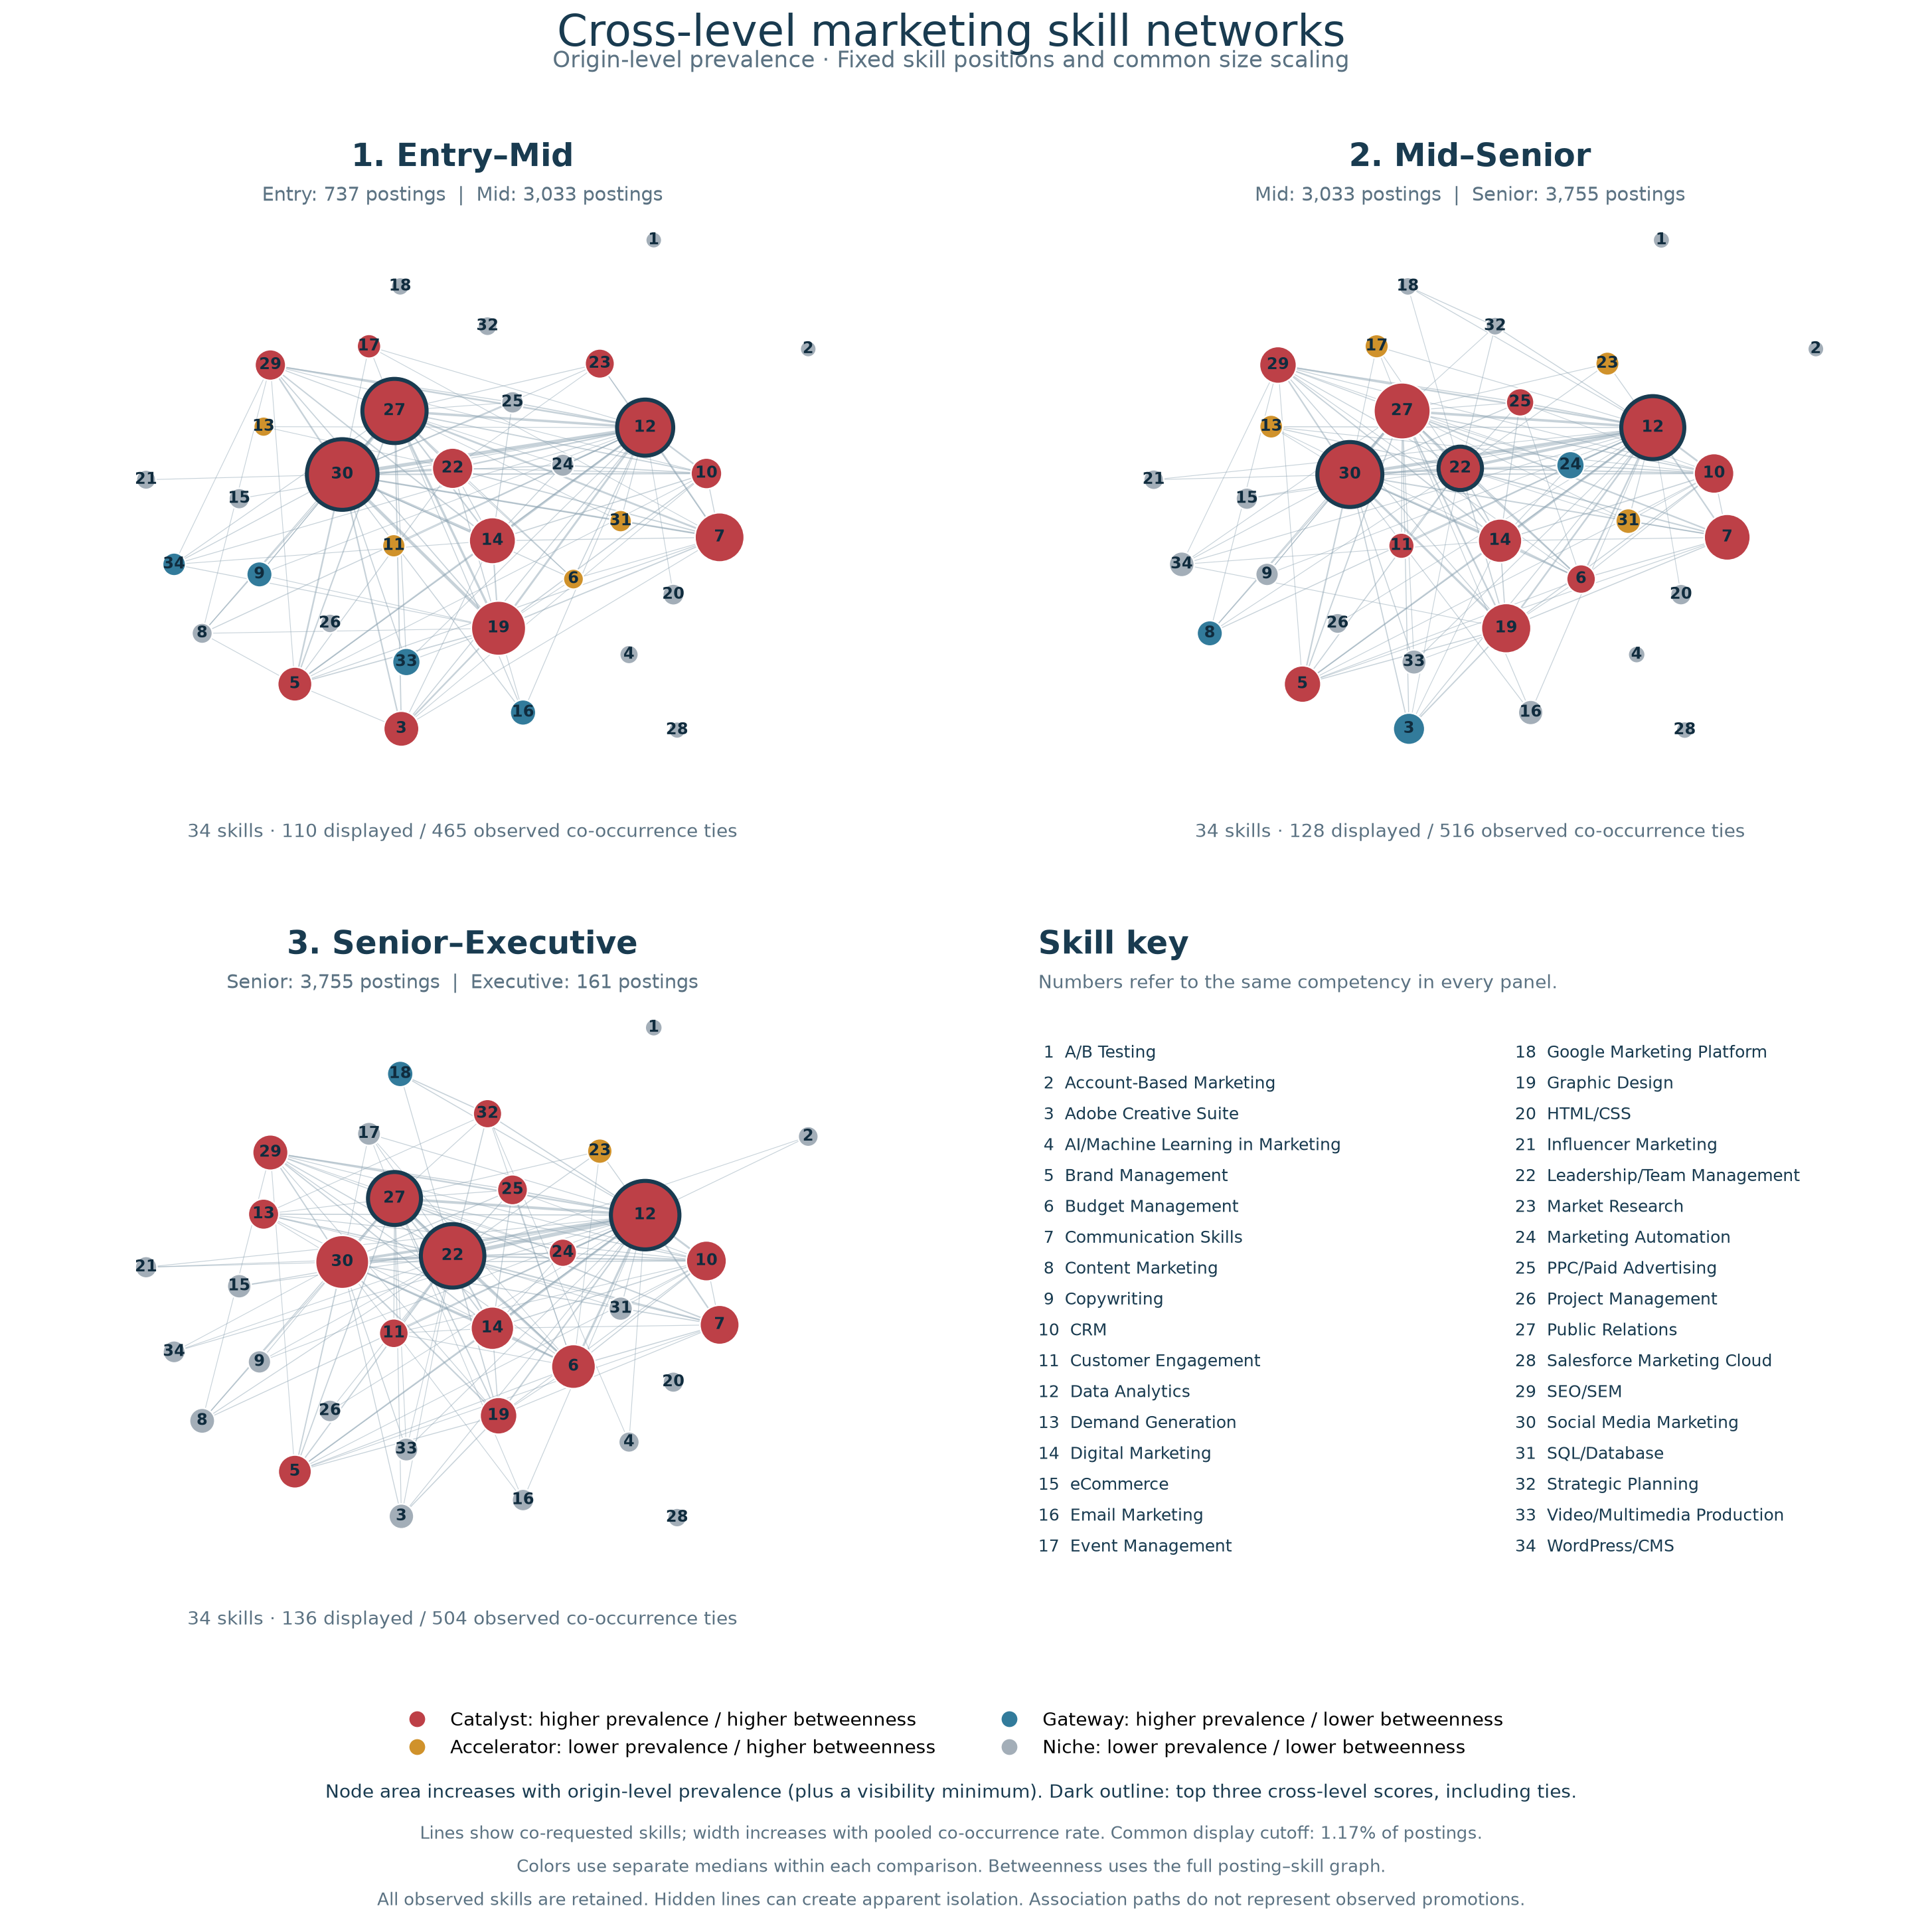

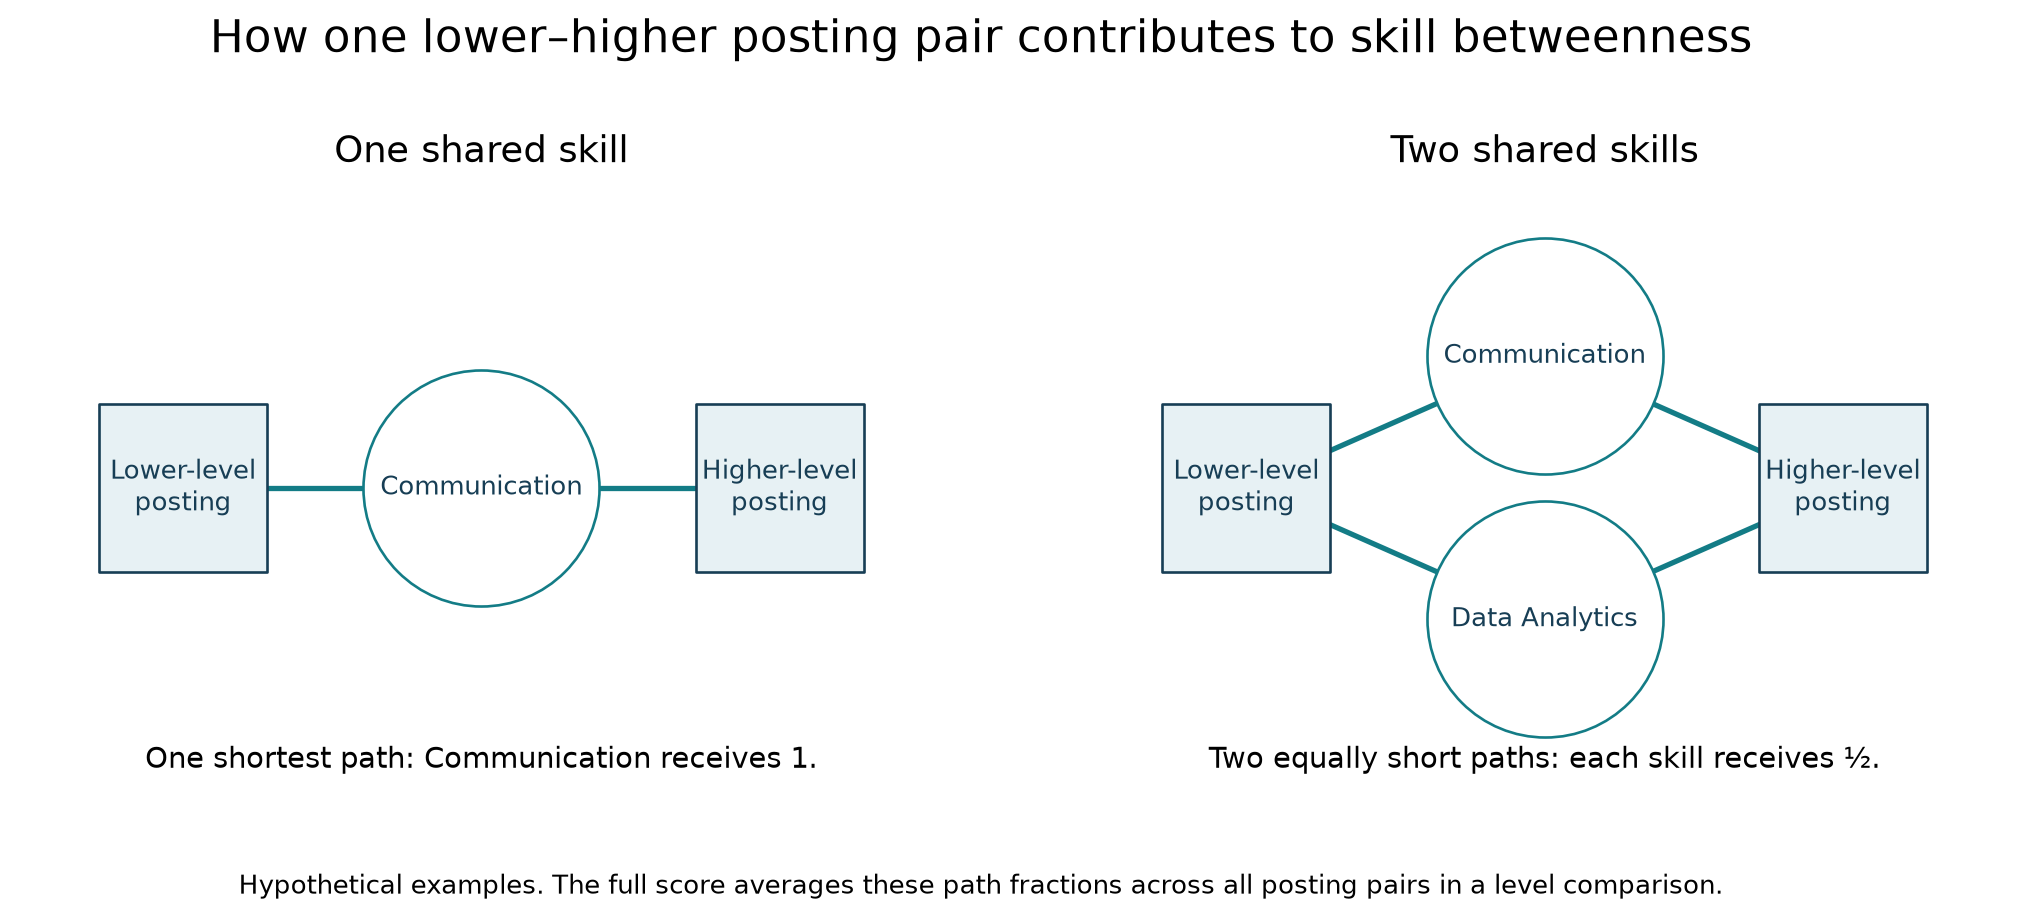

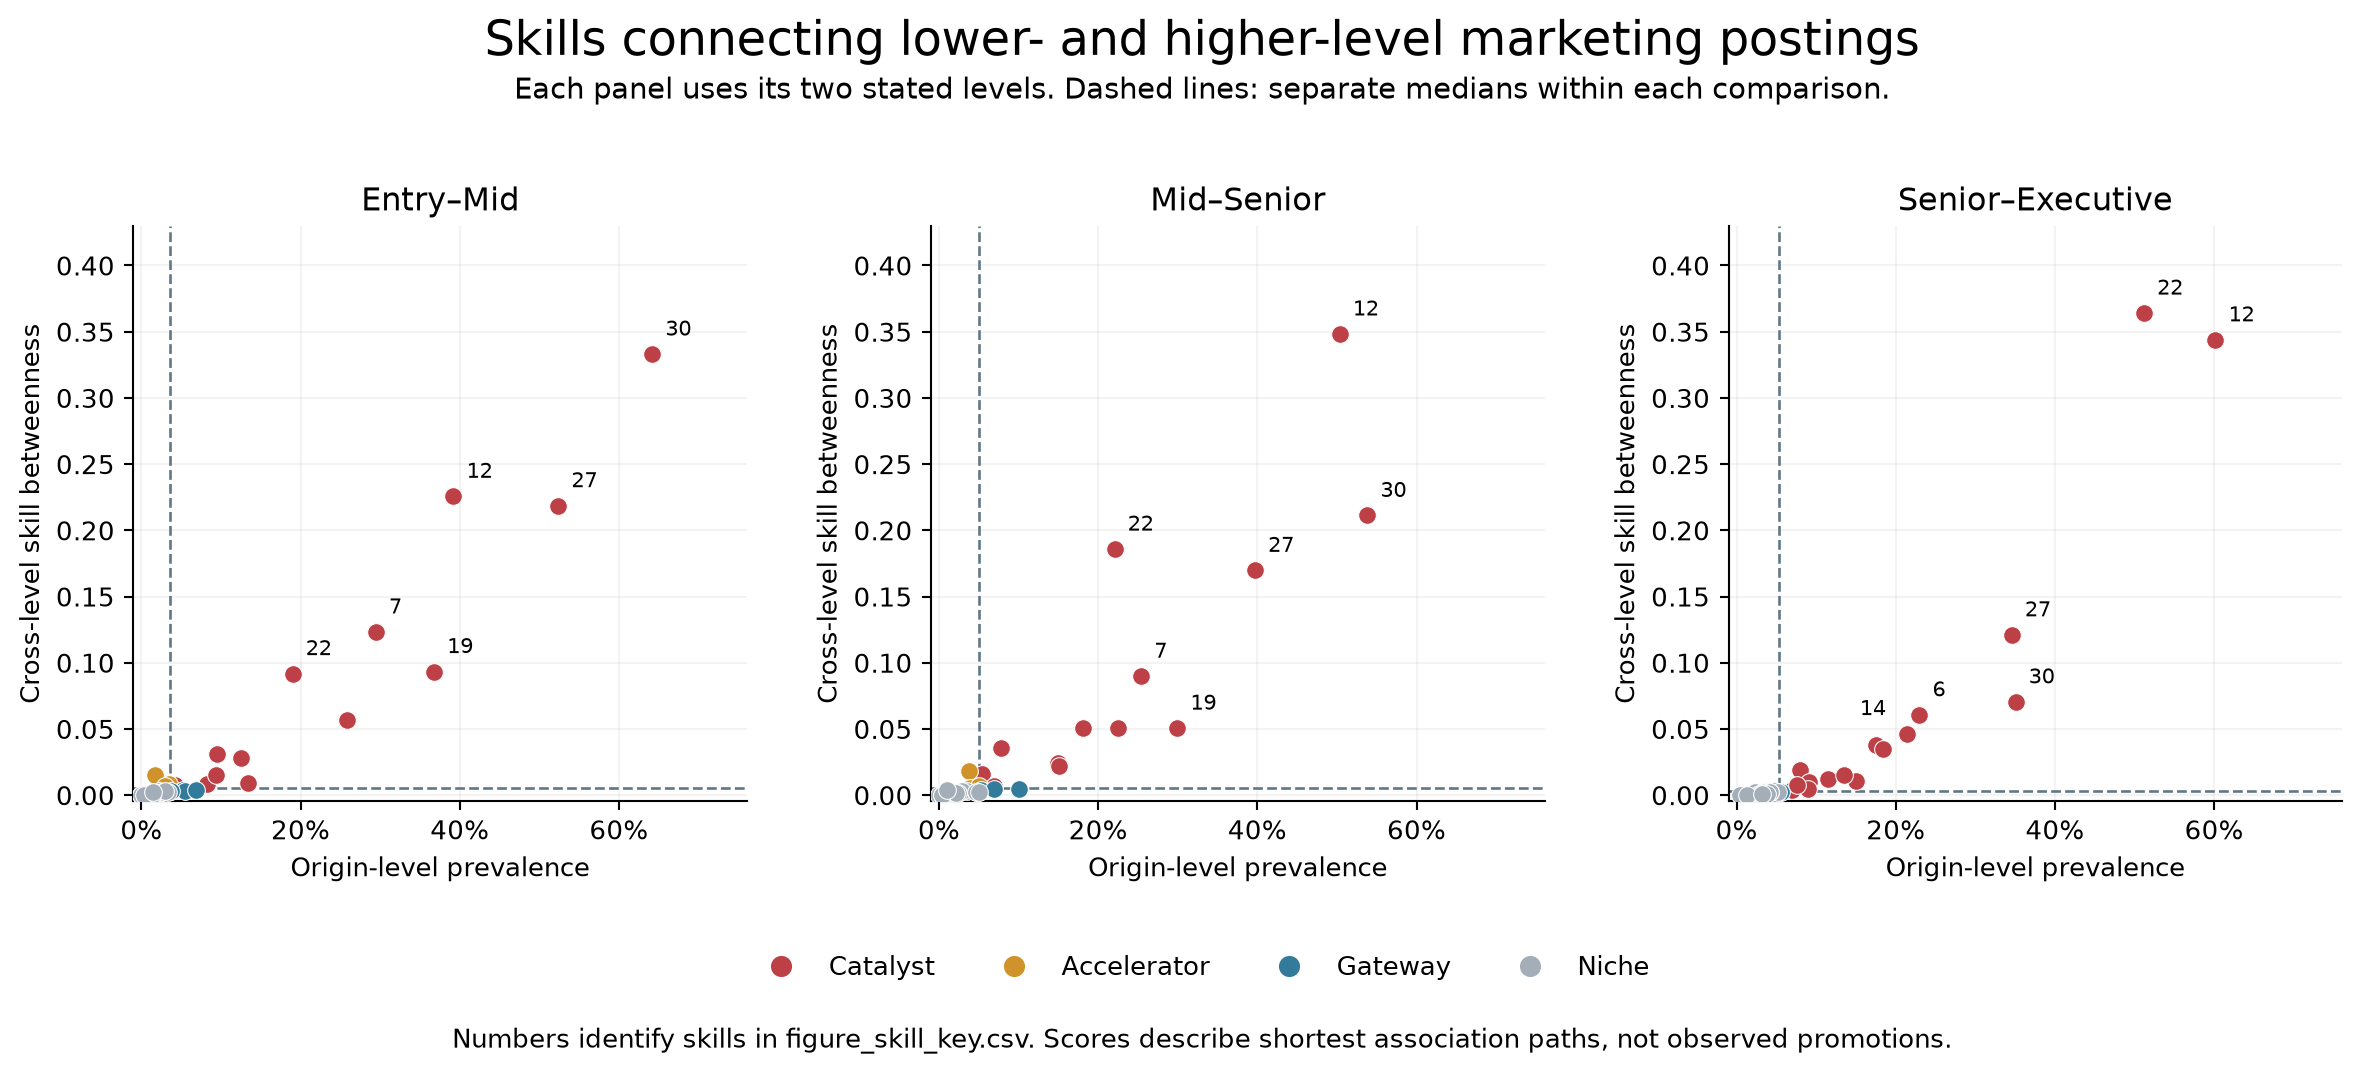

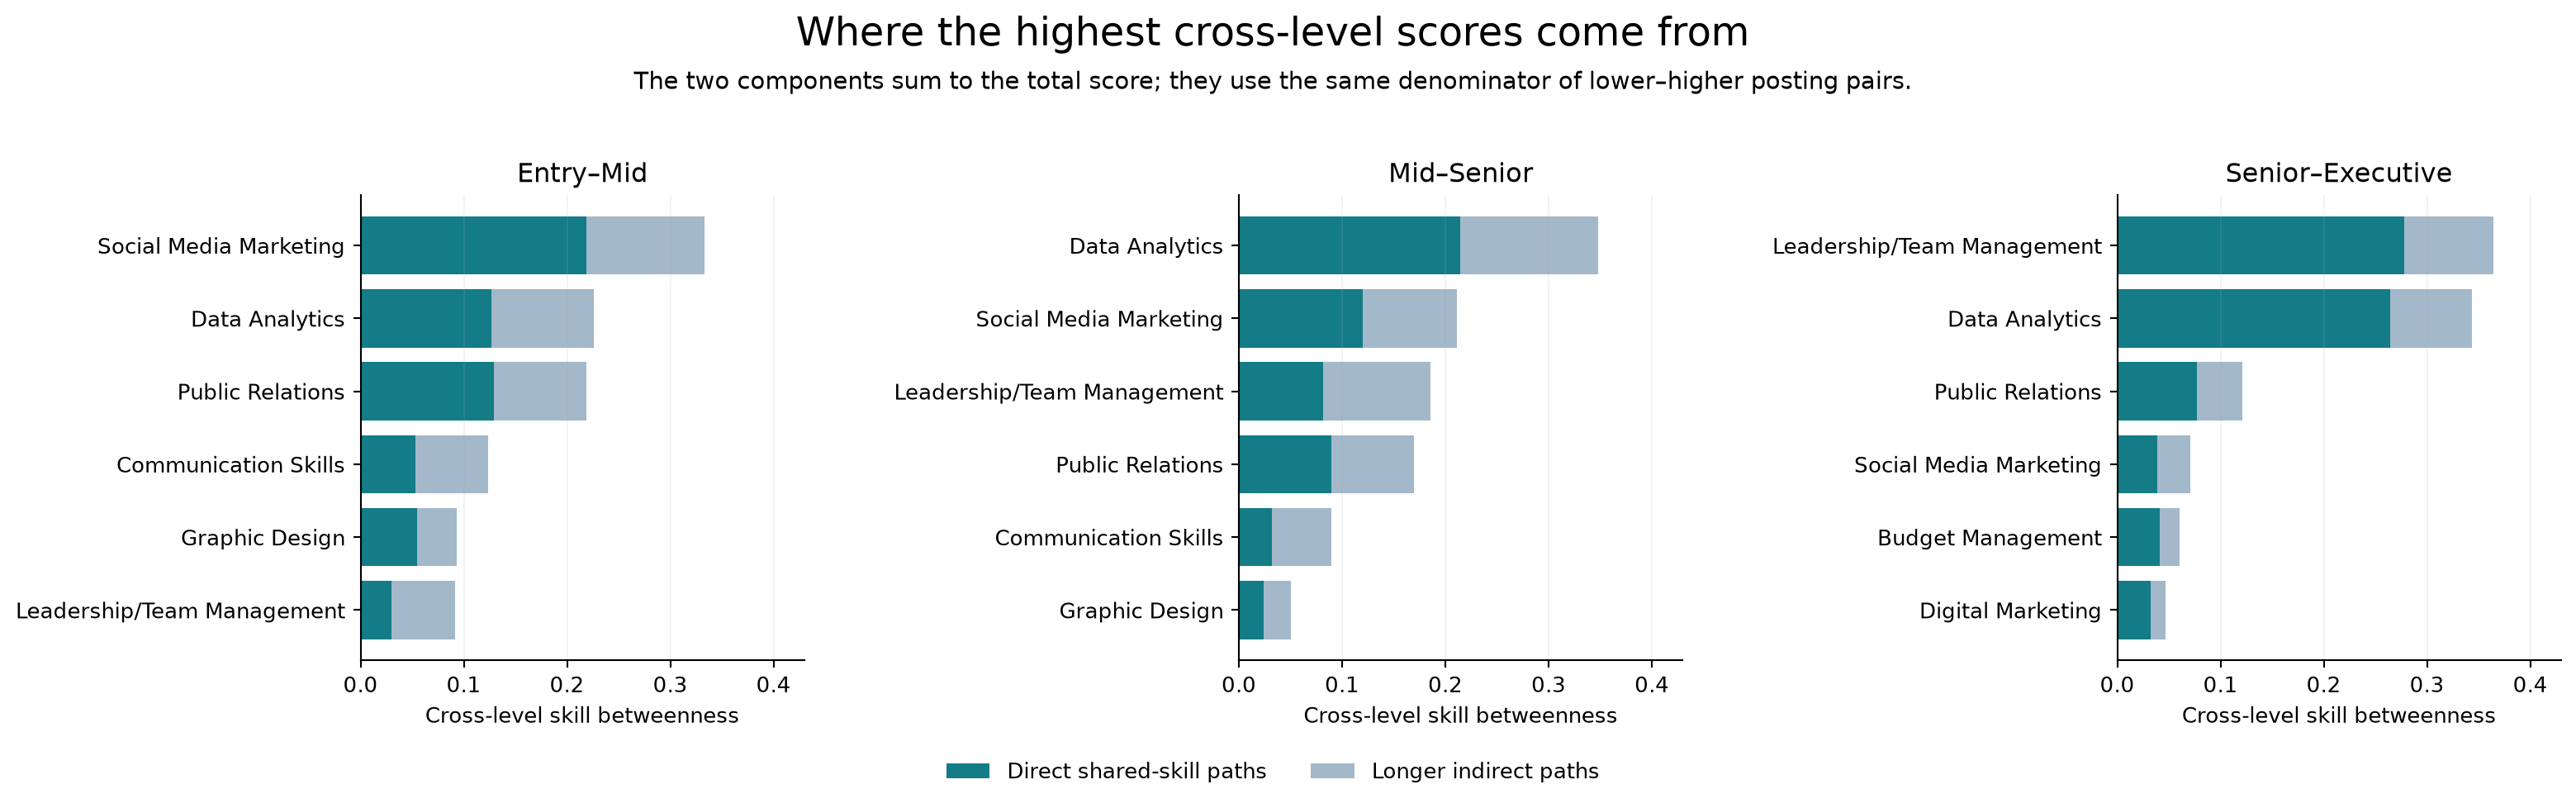

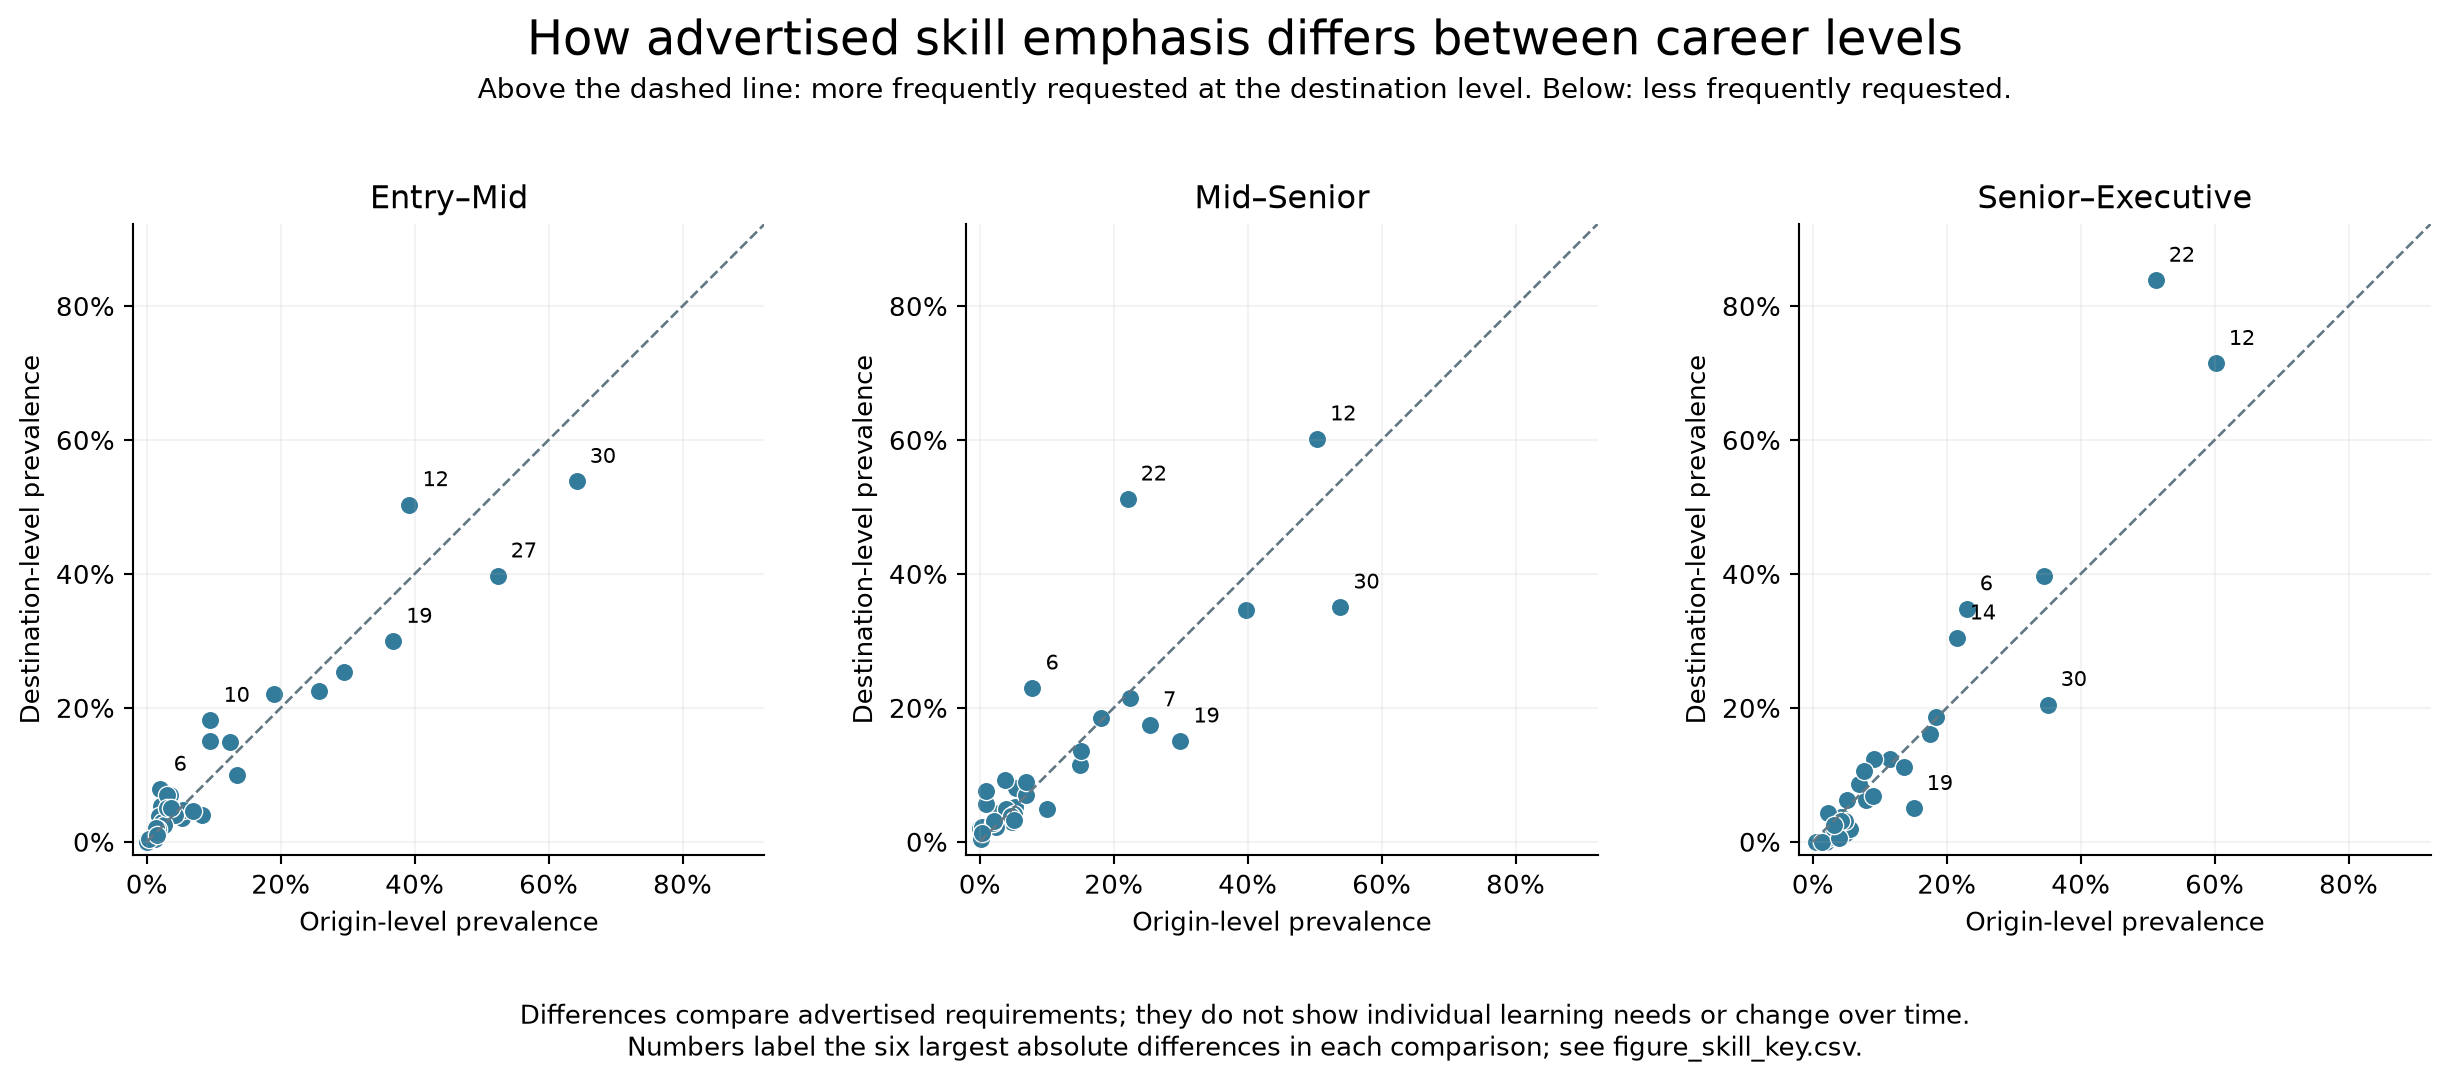

,point_number,skill,skill_label
0,1,a/b testing,A/B Testing
1,2,account-based marketing,Account-Based Marketing
2,3,adobe creative suite,Adobe Creative Suite
3,4,ai/machine learning in marketing,AI/Machine Learning in Marketing
4,5,brand management,Brand Management
5,6,budget management,Budget Management
6,7,communication skills,Communication Skills
7,8,content marketing,Content Marketing
8,9,copywriting,Copywriting
9,10,crm,CRM


All output files: /Users/luna/Library/Mobile Documents/com~apple~CloudDocs/Desktop/projects/JobAnalysis/output/cross_level_posting_skill_origin_median_20261001_162649_222093
CROSS-LEVEL ANALYSIS COMPLETE


In [1]:
# RUN THIS CELL: settings, complete analysis, tables, and figures.
INPUT_FILE = None  # Finds your workbook automatically on this Mac.
SHEET_NAME = "Marketing Jobs - Recoded"
OUTPUT_DIR = None  # Creates a new output folder beside the workbook.
LEVEL_PAIRS = [("entry", "mid"), ("mid", "senior"), ("senior", "executive")]
CUTOFF_METHOD = "median"  # Origin-level prevalence and betweenness; medians across skills observed in either level.
CUTOFF_QUANTILE = 0.50  # Used only when CUTOFF_METHOD = "quantile"; "mean" is also available.
NETWORK_EDGE_DISPLAY_QUANTILE = 0.75  # VISUAL ONLY: common cutoff on pooled pair-specific co-occurrence rates.
NETWORK_LAYOUT_SEED = 42  # One fixed skill layout across comparisons.
MISSING_SKILL_POLICY = "exclude"  # Keeps the same sample rule as the previous notebook.
CUSTOM_LEVEL_MAPPING = None  # Optional complete raw-label -> stratum dictionary.
MIN_VALID_SKILLS = 1  # Exclude postings with NO valid skill. Set 2–5 only for a stated completeness sensitivity.
BALANCE_REPEATS = 100  # Equal-size sensitivity draws; primary full-sample analysis stays intact. Use 0 to disable.
BALANCE_SAMPLE_SIZE = None  # Smallest eligible career level (161 in the supplied workbook).
BALANCE_SEED = 2026
MOUNT_GOOGLE_DRIVE = False

print("Starting cross-level analysis. Wait for CROSS-LEVEL ANALYSIS COMPLETE.", flush=True)
import importlib.util, subprocess, sys
requirements = {"numpy": "numpy>=1.24", "pandas": "pandas>=2.0", "networkx": "networkx>=3.2",
                "matplotlib": "matplotlib>=3.8", "openpyxl": "openpyxl>=3.1"}
missing = [r for m, r in requirements.items() if importlib.util.find_spec(m) is None]
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    else:
        raise RuntimeError("Use a working Python kernel or Colab. Install these missing packages in that kernel: " + ", ".join(missing))
if MOUNT_GOOGLE_DRIVE:
    if not IN_COLAB:
        raise RuntimeError("Drive mounting is only available in Colab.")
    from google.colab import drive
    drive.mount("/content/drive")


import importlib.util
import sys
import subprocess
from collections import Counter
from itertools import combinations
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import math
import os
import platform
import tempfile
import time
import unicodedata

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "marketing_skill_matplotlib"))
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

LEVELS = ("entry", "mid", "senior", "executive")
LEVEL_MAPPING = {
    "intern/entry-level": "entry", "coordinator/associate": "mid",
    "mid-level/specialist": "mid", "supervisor": "mid",
    "manager": "senior", "senior": "senior", "director": "senior",
    "vice president": "executive", "c-suite/executive": "executive",
    "not specified": None, "": None,
}
MISSING = {"", "not specified", "n/a", "na", "none", "nan", "not available"}
SKILL_COLUMNS = tuple(f"Key Skill {i}" for i in range(1, 6))
COLORS = {"Catalyst": "#BD4047", "Accelerator": "#D0922B", "Gateway": "#327B9B", "Niche": "#A3AEB8"}


def normalize(value):
    if value is None or pd.isna(value):
        return ""
    return " ".join(unicodedata.normalize("NFKC", str(value)).split())


def hash_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def resolve_input(input_path=None):
    if input_path is not None:
        path = Path(input_path).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(f"Workbook not found: {path}")
        return path
    script_folder = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    roots = [Path.cwd(), script_folder, Path("/Users/sfy5287/Desktop/projects/JobAnalysis")]
    roots += list(Path.cwd().parents)[:3] + list(script_folder.parents)[:3]
    # Search locally; Drive access is never mounted implicitly.
    for name in ("US_Marketing_Jobs_Recoded.xlsx", "US_Marketing_Jobs_Recoded (1).xlsx"):
        for root in dict.fromkeys(roots):
            path = root / name
            if path.is_file():
                return path.resolve()
    raise FileNotFoundError("Set INPUT_FILE in the notebook, or pass --input /path/to/workbook.xlsx. In Colab, upload the workbook or explicitly mount Drive first.")


def prepare_data(frame, level_mapping=None, missing_skill_policy="exclude"):
    """Clean skill mentions and map observed level labels without guessing."""
    if missing_skill_policy not in {"exclude", "retain"}:
        raise ValueError("missing_skill_policy must be 'exclude' or 'retain'.")
    frame = frame.copy()
    frame.columns = [normalize(c) for c in frame.columns]
    if frame.columns.duplicated().any():
        raise ValueError("Duplicate column names after normalization.")
    needed = ["Job Level", *SKILL_COLUMNS]
    absent = [c for c in needed if c not in frame]
    if absent:
        raise ValueError(f"Required columns missing: {absent}")
    supplied = LEVEL_MAPPING if level_mapping is None else level_mapping
    mapping = {normalize(k).casefold(): normalize(v).casefold() if v is not None else None for k, v in supplied.items()}
    if len(mapping) != len(supplied) or any(v is not None and v not in LEVELS for v in mapping.values()):
        raise ValueError("Level mapping must have unique normalized labels and map to entry, mid, senior, executive, or null.")
    records, display_counts, unmapped = [], {}, Counter()
    for offset, (_, row) in enumerate(frame.iterrows(), 2):
        if row.isna().all():
            continue
        raw_level = normalize(row["Job Level"])
        key = raw_level.casefold()
        if key not in mapping:
            unmapped[raw_level] += 1
            continue
        skills, duplicates, missing_cells = set(), 0, 0
        for col in SKILL_COLUMNS:
            label = normalize(row[col])
            skill = label.casefold()
            if skill in MISSING:
                missing_cells += 1
                continue
            display_counts.setdefault(skill, Counter())[label] += 1
            duplicates += skill in skills
            skills.add(skill)
        level = mapping[key]
        reason = "unspecified_or_excluded_level" if level is None else "no_substantive_skills" if not skills and missing_skill_policy == "exclude" else "included"
        records.append({"excel_row": offset, "posting_id": normalize(row.get("No", offset - 1)), "raw_job_level": raw_level, "stratum": level, "skills": tuple(sorted(skills)), "skill_count": len(skills), "missing_skill_cells": missing_cells, "duplicate_mentions": duplicates, "included": reason == "included", "inclusion_reason": reason})
    if unmapped:
        raise ValueError(f"Unmapped job levels: {dict(unmapped)}. Add an explicit mapping; unknown levels are not automatically assigned to Mid.")
    audit = pd.DataFrame(records)
    if audit.empty:
        raise ValueError("No nonblank job-posting rows were found.")
    labels = {key: counts.most_common(1)[0][0] for key, counts in display_counts.items()}
    jobs = audit[audit["included"]].to_dict("records")
    summary = {
        "input_postings": len(audit), "included_postings": len(jobs),
        "excluded_level": int((audit["inclusion_reason"] == "unspecified_or_excluded_level").sum()),
        "excluded_no_skills_with_known_level": int((audit["inclusion_reason"] == "no_substantive_skills").sum()),
        "no_skills_all_rows": int((audit["skill_count"] == 0).sum()),
        "retained_no_skill_postings": sum(not job["skills"] for job in jobs),
        "distinct_substantive_skills": len({s for job in jobs for s in job["skills"]}),
        "valid_postings_by_level": {level: sum(j["stratum"] == level for j in jobs) for level in LEVELS},
        "known_level_postings_before_skill_filter": {level: int((audit["stratum"] == level).sum()) for level in LEVELS},
    }
    return jobs, audit, labels, summary, mapping


def save_figure(fig, base):
    for ext in ("png", "svg", "pdf"):
        fig.savefig(Path(str(base) + "." + ext), dpi=190, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def annotate_points(ax, points):
    """Place short point IDs without overlapping other labels or plotted points."""
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    occupied = []
    point_pixels = [ax.transData.transform((x, y)) for x, y, _ in points]
    offsets = [(x, y) for y in (7, 20, 33, -17, -30, 46) for x in (5, -18, 18, -32)]
    for x, y, label in points:
        for dx, dy in offsets:
            note = ax.annotate(str(label), (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=8,
                               arrowprops={"arrowstyle": "-", "lw": .4, "color": "#657984"} if abs(dy) > 10 else None)
            box = note.get_window_extent(renderer).expanded(1.1, 1.05)
            # Annotation extents with arrows also include the anchor. Use the text
            # extent alone when checking its placement.
            if note.arrow_patch is not None:
                from matplotlib.text import Text
                box = Text.get_window_extent(note, renderer).expanded(1.1, 1.05)
            if not any(box.overlaps(other) for other in occupied) and not any(box.contains(*p) for p in point_pixels):
                occupied.append(box)
                break
            note.remove()
        else:
            note = ax.annotate(str(label), (x, y), xytext=(5, 58), textcoords="offset points", fontsize=8)
            occupied.append(note.get_window_extent(renderer))

def mask_members(mask):
    result = []
    while mask:
        bit = mask & -mask
        result.append(bit.bit_length() - 1)
        mask ^= bit
    return result


@dataclass
class Bundles:
    """Identical posting skill sets compressed without discarding multiplicity."""
    masks: list[int]
    counts: np.ndarray
    incidence: np.ndarray

    @classmethod
    def from_postings(cls, postings, k):
        counts = Counter(postings)
        masks = sorted(counts)
        incidence = np.zeros((len(masks), k), dtype=float)
        for row, mask in enumerate(masks):
            incidence[row, mask_members(mask)] = 1.0
        return cls(masks, np.asarray([counts[m] for m in masks], dtype=np.int64), incidence)

    def with_counts(self, counts):
        return Bundles(self.masks, np.asarray(counts, dtype=np.int64), self.incidence)

    def active(self):
        keep = self.counts > 0
        return Bundles([m for m, yes in zip(self.masks, keep) if yes], self.counts[keep], self.incidence[keep])

    @property
    def n(self):
        return int(self.counts.sum())

    def frequencies(self):
        return self.counts @ self.incidence

    def resample(self, rng):
        # This is exactly posting-level sampling with replacement after grouping
        # duplicate skill sets. Each bootstrap posting remains a distinct node.
        return self.with_counts(rng.multinomial(self.n, self.counts / self.n))


def bridge_scores(lower: Bundles, higher: Bundles):
    """Exact restricted betweenness using a multiplicity-preserving reduction.

    W[i,j] counts posting nodes offering a two-edge skill i -> posting -> skill j
    route. It counts alternative routes, NOT distance or tie strength for a
    weighted shortest-path algorithm. BFS takes every projected hop as one step.
    Paths are counted with W multiplicities; target contributions are injected
    at their nearest skills, then propagated backward. This is equivalent to
    BFS on the original unweighted bipartite graph (see tests and README).
    """
    if lower.n == 0 or higher.n == 0:
        raise ValueError("Both career levels must contain at least one posting.")
    lower, higher = lower.active(), higher.active()
    # Undirected symmetry permits fewer distinct source bundles for speed.
    if len(lower.masks) > len(higher.masks):
        lower, higher = higher, lower
    k = lower.incidence.shape[1]
    w = lower.incidence.T @ (lower.incidence * lower.counts[:, None])
    w += higher.incidence.T @ (higher.incidence * higher.counts[:, None])
    np.fill_diagonal(w, 0.0)
    count_sources = len(lower.masks)
    distance = np.full((count_sources, k), -1, dtype=np.int32)
    frontier = lower.incidence.copy()
    sigma = frontier.copy()
    distance[frontier > 0] = 0
    depth = 0
    while np.any(frontier):
        candidates = frontier @ w
        new = (distance < 0) & (candidates > 0)
        if not np.any(new):
            break
        depth += 1
        frontier = np.where(new, candidates, 0.0)
        sigma += frontier
        distance[new] = depth
    if not np.all(np.isfinite(sigma)):
        raise FloatingPointError("Shortest-path counts overflowed. Graph requires higher-precision path counting.")

    dependency = np.zeros_like(sigma)
    reachable_pairs = 0
    for mask, multiplicity in zip(higher.masks, higher.counts):
        idx = mask_members(mask)
        if not idx:
            continue
        target_distances = distance[:, idx]
        minimum = np.min(np.where(target_distances >= 0, target_distances, k + 1), axis=1)
        nearest = (target_distances == minimum[:, None]) & (target_distances >= 0)
        target_paths = sigma[:, idx] * nearest
        denominators = target_paths.sum(axis=1)
        dependency[:, idx] += np.divide(target_paths, denominators[:, None], out=np.zeros_like(target_paths), where=denominators[:, None] > 0) * multiplicity
        reachable_pairs += int(lower.counts[denominators > 0].sum()) * int(multiplicity)
    for layer in range(depth, 0, -1):
        ratios = np.divide(dependency, sigma, out=np.zeros_like(sigma), where=(distance == layer) & (sigma > 0))
        previous = sigma * (ratios @ w.T)
        dependency += np.where(distance == layer - 1, previous, 0.0)
    pairs = lower.n * higher.n
    score = (lower.counts @ dependency) / pairs
    if np.any(score < -1e-12) or np.any(score > 1 + 1e-12):
        raise ArithmeticError("A skill score fell outside [0, 1].")
    return score, {"eligible_pairs": pairs, "reachable_pairs": reachable_pairs, "reachable_pair_share": reachable_pairs / pairs, "max_skill_hops": depth}

def direct_shared_scores(lower, higher):
    """Contribution from two-edge paths through a directly shared skill."""
    k = lower.incidence.shape[1]
    total = np.zeros(k)
    shared_pairs = 0
    for mask, count in zip(lower.masks, lower.counts):
        idx = mask_members(mask)
        if not idx:
            continue
        overlap = higher.incidence[:, idx]
        nshared = overlap.sum(axis=1)
        contribution = np.divide(higher.counts, nshared, out=np.zeros(len(nshared)), where=nshared > 0)
        total[idx] += count * (contribution @ overlap)
        shared_pairs += int(count) * int(higher.counts[nshared > 0].sum())
    return total / (lower.n * higher.n), shared_pairs


def validate_cutoff_settings(method, quantile=.5):
    if method not in {'mean', 'median', 'quantile'}:
        raise ValueError('CUTOFF_METHOD must be mean, median, or quantile.')
    if method == 'quantile' and not 0 < quantile < 1:
        raise ValueError('CUTOFF_QUANTILE must be strictly between 0 and 1.')


def classification_cutoff(values, method='median', quantile=.5):
    """Unweighted skill-level cutoffs; callers supply the same eligible reference set."""
    validate_cutoff_settings(method, quantile)
    values = np.asarray(values, dtype=float)
    if values.size == 0:
        return math.nan
    if not np.isfinite(values).all():
        raise ValueError('Classification cutoffs require finite eligible scores.')
    if method == 'mean':
        return float(np.mean(values))
    if method == 'median':
        return float(np.median(values))
    return float(np.quantile(values, quantile))


def cutoff_description(method, quantile=.5):
    return {'mean': 'arithmetic means', 'median': 'medians'}.get(method, f'{quantile:g} quantiles')


def mobility_category(prevalence, betweenness, prevalence_cutoff, betweenness_cutoff):
    high_p, high_b = prevalence > prevalence_cutoff, betweenness > betweenness_cutoff
    return 'Catalyst' if high_p and high_b else 'Gateway' if high_p else 'Accelerator' if high_b else 'Niche'


def compare_cross_level_cutoffs(scores):
    """Compare mean and median labels without changing scores or eligible skills."""
    detail, thresholds = [], []
    for comparison, part in scores.groupby('comparison', sort=False):
        cuts = {}
        for method in ('mean', 'median'):
            xcut = classification_cutoff(part.origin_prevalence, method)
            ycut = classification_cutoff(part.cross_level_betweenness, method)
            cuts[method] = (xcut, ycut)
            thresholds.append({'comparison': comparison, 'cutoff_method': method,
                               'origin_prevalence_cutoff': xcut, 'cross_level_betweenness_cutoff': ycut,
                               'skills_in_reference': len(part), 'tie_rule': 'equal_is_lower'})
        for row in part.itertuples():
            mean = mobility_category(row.origin_prevalence, row.cross_level_betweenness, *cuts['mean'])
            median = mobility_category(row.origin_prevalence, row.cross_level_betweenness, *cuts['median'])
            detail.append({'comparison': comparison, 'skill': row.skill, 'skill_label': row.skill_label,
                           'origin_prevalence': row.origin_prevalence, 'cross_level_betweenness': row.cross_level_betweenness,
                           'mean_category': mean, 'median_category': median, 'category_changed': mean != median})
    detail = pd.DataFrame(detail)
    summary = detail.groupby('comparison', sort=False).agg(
        skills=('skill', 'size'), changed_categories=('category_changed', 'sum')).reset_index()
    summary['changed_share'] = summary.changed_categories / summary.skills
    return detail, pd.DataFrame(thresholds), summary


def compare_prevalence_bases(scores, cutoff_method='median', cutoff_quantile=.5):
    """Assess the effect of selecting origin versus destination demand on fixed scores."""
    records=[]
    for comparison, part in scores.groupby('comparison',sort=False):
        origin_cut=classification_cutoff(part.origin_prevalence,cutoff_method,cutoff_quantile)
        destination_cut=classification_cutoff(part.destination_prevalence,cutoff_method,cutoff_quantile)
        between_cut=classification_cutoff(part.cross_level_betweenness,cutoff_method,cutoff_quantile)
        for r in part.itertuples():
            origin=mobility_category(r.origin_prevalence,r.cross_level_betweenness,origin_cut,between_cut)
            destination=mobility_category(r.destination_prevalence,r.cross_level_betweenness,destination_cut,between_cut)
            records.append({'comparison':comparison,'skill':r.skill,'skill_label':r.skill_label,
                'origin_prevalence':r.origin_prevalence,'destination_prevalence':r.destination_prevalence,
                'cross_level_betweenness':r.cross_level_betweenness,'cutoff_method':cutoff_method,
                'origin_prevalence_cutoff':origin_cut,'destination_prevalence_cutoff':destination_cut,
                'betweenness_cutoff':between_cut,'origin_category':origin,'destination_category':destination,
                'category_changed':origin!=destination})
    detail=pd.DataFrame(records)
    summary=detail.groupby('comparison',sort=False).agg(skills=('skill','size'),
        changed_categories=('category_changed','sum')).reset_index()
    return detail,summary


def prevalence_alternatives(scores):
    """Descriptive alternatives; no alternate four-category labels or mobility effects."""
    cols = ['comparison', 'skill', 'skill_label', 'n_lower', 'n_higher',
            'lower_postings_requesting_skill', 'higher_postings_requesting_skill',
            'source_prevalence', 'target_prevalence', 'origin_prevalence', 'destination_prevalence', 'cross_level_betweenness',
            'direct_shared_component', 'indirect_path_component', 'category']
    table = scores[cols].copy()
    lower, higher = table.source_prevalence.to_numpy(), table.target_prevalence.to_numpy()
    table['prevalence_difference'] = higher - lower
    table['prevalence_difference_pp'] = 100 * (higher - lower)
    table['prevalence_ratio_raw'] = np.divide(higher, lower, out=np.full(len(table), np.nan), where=lower > 0)
    table['ratio_status'] = np.where(lower == 0, 'undefined_source_zero',
                                    np.where(higher == 0, 'zero_target_prevalence', 'defined'))
    # Add one-half to both binary outcome cells at each level: (n + .5) / (N + 1).
    # This is a declared descriptive sensitivity; it creates no observed counts.
    ps = (table.lower_postings_requesting_skill + .5) / (table.n_lower + 1)
    pt = (table.higher_postings_requesting_skill + .5) / (table.n_higher + 1)
    table['log2_prevalence_ratio_half_count'] = np.log2(pt / ps)
    table['shared_requirement_pair_coverage'] = lower * higher
    table['target_count_below_10'] = table.higher_postings_requesting_skill < 10
    table['source_count_below_10'] = table.lower_postings_requesting_skill < 10
    table['indirect_share_of_betweenness'] = np.divide(
        table.indirect_path_component, table.cross_level_betweenness,
        out=np.full(len(table), np.nan), where=table.cross_level_betweenness > 0)
    assert (table.direct_shared_component <= table.shared_requirement_pair_coverage + 1e-12).all()
    diagnostics = []
    for comparison, part in table.groupby('comparison', sort=False):
        for measure in ['origin_prevalence', 'destination_prevalence', 'prevalence_difference',
                        'prevalence_ratio_raw', 'log2_prevalence_ratio_half_count',
                        'shared_requirement_pair_coverage']:
            valid = part[[measure, 'cross_level_betweenness']].dropna()
            x, y = valid[measure], valid.cross_level_betweenness
            correlate = lambda a, b: float(a.corr(b)) if len(a) > 1 and a.nunique() > 1 and b.nunique() > 1 else np.nan
            diagnostics.append({'comparison': comparison, 'measure': measure, 'skills': len(valid),
                                'pearson_with_betweenness': correlate(x, y),
                                'spearman_with_betweenness': correlate(x.rank(method='average'), y.rank(method='average'))})
    return table, pd.DataFrame(diagnostics)


def write_measurement_note(alternatives, diagnostics, output):
    report = [
        '# Interpreting origin-level prevalence and supplementary measures', '',
        'The primary matrix uses origin-level prevalence: the fraction of eligible postings at the starting career level requesting a skill. The alternatives below are supplementary diagnostics, not validated measures of promotion or substitutes chosen to produce particular categories.', '',
        'Let p_L = n_L/N_L and p_H = n_H/N_H, where n counts postings requesting a skill and N counts eligible postings at each selected level. Requirements are cross-sectional and limited to the skills extracted from advertisements.', '',
        '| Measure | Calculation | Interpretation and limitation |',
        '|---|---|---|',
        '| Origin demand | p_L | How commonly a skill is requested at the starting level; not evidence that an individual possesses it. |',
        '| Destination demand | p_H | How commonly the target level requests a skill; not a measure of transferability, proficiency, or advancement. |',
        '| Difference in advertised emphasis | 100(p_H − p_L) | Percentage-point difference between levels. Zero is the natural reference. Not change over time or an individual learning gap. |',
        '| Relative emphasis | p_H / p_L | Relative frequency at the destination; 1 is the natural reference. Undefined when source prevalence is zero and sensitive to small counts. |',
        '| Log relative emphasis, sensitivity only | log2{[(n_H + 0.5)/(N_H + 1)] / [(n_L + 0.5)/(N_L + 1)]} | Explicit half-count adjustment keeps zeros finite; estimates for small counts depend on this convention. Raw counts and unadjusted ratios are retained. |',
        '| Shared-requirement pair coverage | p_L p_H | Fraction of all lower–higher posting pairs that both request the focal skill. Transparent continuity measure, but driven by prevalence and not a network-brokerage measure. |', '',
        'Below-10-count flags are descriptive prompts to inspect sparse observations, not statistical significance thresholds. No observations are removed by these flags.', '',
        '## Recommended use', '',
        'Origin-level prevalence locates a skill within the advertised requirements of the starting career level. Cross-level betweenness describes its participation in association paths linking that level with the destination. Report destination prevalence and the percentage-point difference as additional context. Neither origin demand nor network position establishes individual skill possession, readiness, or a promotion effect.', '',
        'A high betweenness score can follow from many postings requesting the same skill. Strong correlation with prevalence means that the matrix axes supply overlapping information; switching from median to mean does not remove this dependence. A further test of bridging beyond frequency could compare observed scores with randomized posting–skill networks preserving each posting’s skill count and each skill’s frequency separately within each level. Such a test has not been run here, and would not establish causal mobility effects.', '',
        '## Profile interpretation and correlation', '',
        'Catalyst: higher origin prevalence and higher betweenness. Accelerator: lower origin prevalence and higher betweenness. Gateway: higher origin prevalence and lower betweenness. Niche: lower values on both. Gateway now describes common origin-level requirements; it must not be interpreted as evidence of destination entry requirements. The labels are descriptive and do not imply actual acceleration or entry.', '',
        '| Comparison | Pearson correlation | Spearman correlation |', '|---|---:|---:|',
    ]
    for r in diagnostics[diagnostics.measure == 'origin_prevalence'].itertuples():
        report.append(f'| {r.comparison} | {r.pearson_with_betweenness:.3f} | {r.spearman_with_betweenness:.3f} |')
    report += ['', '## Selected examples', '',
               '| Comparison | Skill | Origin prevalence | Destination prevalence | Difference, percentage points |',
               '|---|---|---:|---:|---:|']
    selected = alternatives[(alternatives.comparison == 'Mid–Senior') & alternatives.skill_label.isin(
        ['Leadership/Team Management', 'Data Analytics', 'Social Media Marketing', 'SQL/Database'])]
    for r in selected.itertuples():
        report.append(f'| {r.comparison} | {r.skill_label} | {r.source_prevalence:.1%} | {r.target_prevalence:.1%} | {r.prevalence_difference_pp:+.1f} |')
    report += ['', '## Theoretical grounding', '',
        'Lazear’s skill-weights approach explains why combinations and their relative importance matter across firms; it does not imply that a frequently advertised skill causes advancement. [Lazear (2009)](https://www.journals.uchicago.edu/doi/10.1086/648671).', '',
        'Gathmann and Schönberg connect occupational moves to similarities in task requirements. This supports studying overlap between source and target work; empirical validation of mobility requires observed worker outcomes. [Gathmann and Schönberg (2010)](https://www.journals.uchicago.edu/doi/10.1086/649786).', '',
        'Alabdulkareem and colleagues use relative skill importance to distinguish specialized requirements from ubiquitous ones. Their O*NET-based revealed-comparative-advantage measure is not identical to the posting-prevalence ratio above; the ratio is a descriptive adaptation for the present two-level comparison. [Alabdulkareem et al. (2018)](https://pmc.ncbi.nlm.nih.gov/articles/PMC6051733/).', '',
        'These theoretical arguments motivate the questions. They do not validate the proposed diagnostic measures as causal indicators.']
    (output/'measurement_alternatives.md').write_text('\n'.join(report)+'\n', encoding='utf-8')


def plot_source_target_prevalence(scores, key, output):
    comparisons = scores.comparison.drop_duplicates().tolist()
    fig, axes = plt.subplots(1, len(comparisons), figsize=(5.2*len(comparisons), 5.6), squeeze=False)
    limit = min(1, max(scores.source_prevalence.max(), scores.target_prevalence.max()) * 1.10)
    numbers = key.set_index('skill').point_number.to_dict()
    panels = []
    for ax, comparison in zip(axes.flat, comparisons):
        part = scores[scores.comparison == comparison]
        ax.plot([0, limit], [0, limit], '--', color='#617783', linewidth=1)
        ax.scatter(part.source_prevalence, part.target_prevalence, s=48, color='#327B9B', edgecolors='white', linewidths=.5)
        labels = part.assign(difference=(part.target_prevalence-part.source_prevalence).abs()).nlargest(6, 'difference')
        panels.append((ax, [(r.source_prevalence,r.target_prevalence,numbers[r.skill]) for r in labels.itertuples()]))
        ax.set(xlim=(-.02,limit), ylim=(-.02,limit), xlabel='Origin-level prevalence', ylabel='Destination-level prevalence', title=comparison)
        ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.spines[['top','right']].set_visible(False); ax.grid(alpha=.15)
        ax.set_aspect('equal', adjustable='box')
    fig.suptitle('How advertised skill emphasis differs between career levels', fontsize=18, y=.99)
    fig.text(.5,.915,'Above the dashed line: more frequently requested at the destination level. Below: less frequently requested.',ha='center',fontsize=10.5)
    fig.text(.5,.045,'Differences compare advertised requirements; they do not show individual learning needs or change over time.',ha='center',fontsize=10)
    fig.text(.5,.015,'Numbers label the six largest absolute differences in each comparison; see figure_skill_key.csv.',ha='center',fontsize=10)
    fig.subplots_adjust(top=.80,bottom=.20,wspace=.32)
    for ax, points in panels:
        annotate_points(ax,points)
    save_figure(fig,output/'source_target_prevalence_comparison')



def illustrative_figure(output):
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
    navy, teal, pale = '#173E55', '#137C86', '#E7F1F4'
    for i, ax in enumerate(axes):
        nodes = {'lower': 'Lower-level\nposting', 'higher': 'Higher-level\nposting', 'communication': 'Communication'}
        positions = {'lower': (-1, 0), 'higher': (1, 0), 'communication': (0, .45 if i else 0)}
        edges = [('lower', 'communication'), ('communication', 'higher')]
        if i:
            nodes['analytics'] = 'Data Analytics'
            positions['analytics'] = (0, -.45)
            edges += [('lower', 'analytics'), ('analytics', 'higher')]
        graph = nx.Graph(edges)
        nx.draw_networkx_edges(graph, positions, ax=ax, edge_color=teal, width=2)
        nx.draw_networkx_nodes(graph, positions, nodelist=['lower', 'higher'], node_shape='s', node_size=4100, node_color=pale, edgecolors=navy, ax=ax)
        skills = [n for n in graph if n not in {'lower', 'higher'}]
        nx.draw_networkx_nodes(graph, positions, nodelist=skills, node_size=8000, node_color='white', edgecolors=teal, ax=ax)
        nx.draw_networkx_labels(graph, positions, labels=nodes, font_size=10, font_color=navy, ax=ax)
        ax.set_title('One shared skill' if not i else 'Two shared skills', fontsize=14, pad=18)
        ax.text(.5, -.02, 'One shortest path: Communication receives 1.' if not i else 'Two equally short paths: each skill receives ½.', transform=ax.transAxes, ha='center', fontsize=11)
        ax.set_xlim(-1.55, 1.55); ax.set_ylim(-.92, .95); ax.axis('off')
    fig.suptitle('How one lower–higher posting pair contributes to skill betweenness', fontsize=17, y=.98)
    fig.text(.5, .02, 'Hypothetical examples. The full score averages these path fractions across all posting pairs in a level comparison.', ha='center', fontsize=10)
    fig.subplots_adjust(top=.77, bottom=.17, wspace=.15)
    save_figure(fig, output / 'how_cross_level_betweenness_works')


def cross_level_figures(scores, thresholds, key, output, cutoff_method='median', cutoff_quantile=.5):
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'svg.fonttype': 'none', 'pdf.fonttype': 42})
    illustrative_figure(output)
    comparisons = scores.comparison.drop_duplicates().tolist()
    n = len(comparisons)
    numbers = key.set_index('skill').point_number.to_dict()
    fig, axes = plt.subplots(1, n, figsize=(5.0*n, 5.6), squeeze=False)
    xmax = min(1, scores.origin_prevalence.max()*1.17 + .01)
    ymax = min(1.05, max(.01, scores.cross_level_betweenness.max()*1.18))
    label_panels = []
    for ax, comparison in zip(axes.flat, comparisons):
        subset = scores[scores.comparison == comparison]
        cut = thresholds[thresholds.comparison == comparison].iloc[0]
        for category, color in COLORS.items():
            part = subset[subset.category == category]
            ax.scatter(part.origin_prevalence, part.cross_level_betweenness, c=color, s=45, edgecolors='white', linewidths=.4, zorder=3)
        ax.axvline(cut.origin_prevalence_cutoff, ls='--', color='#617783', lw=1)
        ax.axhline(cut.cross_level_betweenness_cutoff, ls='--', color='#617783', lw=1)
        ax.set(xlim=(-.01, xmax), ylim=(-.01*ymax, ymax), xlabel='Origin-level prevalence', ylabel='Cross-level skill betweenness', title=comparison)
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.spines[['top', 'right']].set_visible(False); ax.grid(alpha=.15)
        label_panels.append((ax, [(r.origin_prevalence, r.cross_level_betweenness, numbers[r.skill]) for r in subset.nlargest(6, 'cross_level_betweenness').itertuples()]))
    fig.suptitle('Skills connecting lower- and higher-level marketing postings', fontsize=18, y=.985)
    cutoff_text = cutoff_description(cutoff_method, cutoff_quantile)
    fig.text(.5, .91, f'Each panel uses its two stated levels. Dashed lines: separate {cutoff_text} within each comparison.', ha='center', fontsize=11)
    handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=9, label=category) for category, color in COLORS.items()]
    fig.legend(handles=handles, loc='lower center', ncol=4, bbox_to_anchor=(.5, .058), frameon=False)
    fig.text(.5, .018, 'Numbers identify skills in figure_skill_key.csv. Scores describe shortest association paths, not observed promotions.', ha='center', fontsize=10)
    fig.subplots_adjust(top=.79, bottom=.25, wspace=.3)
    for ax, points in label_panels:
        annotate_points(ax, points)
    save_figure(fig, output / f'cross_level_origin_{cutoff_method}_matrix')

    fig, axes = plt.subplots(1, n, figsize=(5.7*n, 5.2), squeeze=False)
    for ax, comparison in zip(axes.flat, comparisons):
        top = scores[scores.comparison == comparison].nlargest(6, 'cross_level_betweenness').iloc[::-1]
        y = np.arange(len(top))
        ax.barh(y, top.direct_shared_component, color='#137C86', label='Direct shared-skill paths')
        ax.barh(y, top.indirect_path_component, left=top.direct_shared_component, color='#A3B8C9', label='Longer indirect paths')
        ax.set_yticks(y, top.skill_label)
        ax.set(xlabel='Cross-level skill betweenness', title=comparison)
        ax.set_xlim(0, ymax)
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='x', alpha=.15)
    fig.suptitle('Where the highest cross-level scores come from', fontsize=18, y=.99)
    fig.text(.5, .90, 'The two components sum to the total score; they use the same denominator of lower–higher posting pairs.', ha='center', fontsize=11)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, ncol=2, loc='lower center', bbox_to_anchor=(.5, .025), frameon=False)
    fig.subplots_adjust(top=.77, bottom=.20, left=.16, right=.98, wspace=.98)
    save_figure(fig, output / 'top_cross_level_skills')


def cross_level_network_figures(jobs, scores, key, output, edge_display_quantile=.75, layout_seed=42, cutoff_method='median', cutoff_quantile=.5):
    """Display skill co-occurrences with precomputed cross-level node attributes.

    No centrality is recomputed on these display projections. Each co-occurrence
    is counted once per posting. A single rate cutoff and layout serve all panels.
    """
    if not 0 <= edge_display_quantile <= 1:
        raise ValueError('network_edge_display_quantile must be between zero and one.')
    comparisons = scores.comparison.drop_duplicates().tolist()
    numbers = key.set_index('skill').point_number.to_dict()
    labels = key.set_index('skill').skill_label.to_dict()
    counts_by_level = {level: Counter() for level in LEVELS}
    for job in jobs:
        counts_by_level[job['stratum']].update(combinations(sorted(set(job['skills'])), 2))
    graphs, edge_rows = {}, []
    for comparison in comparisons:
        part = scores[scores.comparison == comparison]
        lower, higher = part.lower_level.iloc[0], part.higher_level.iloc[0]
        nl, nh = int(part.n_lower.iloc[0]), int(part.n_higher.iloc[0])
        lc, hc = counts_by_level[lower], counts_by_level[higher]
        graph = nx.Graph()
        graph.add_nodes_from(sorted(part.skill))
        for a, b in sorted(lc.keys() | hc.keys()):
            rate = (lc[a, b] + hc[a, b]) / (nl + nh)
            graph.add_edge(a, b, cooccurrence_rate=rate)
            edge_rows.append({'comparison': comparison, 'lower_level': lower, 'higher_level': higher,
                              'skill_1': a, 'skill_2': b, 'skill_1_label': labels[a], 'skill_2_label': labels[b],
                              'lower_cooccurrence_count': lc[a, b], 'higher_cooccurrence_count': hc[a, b],
                              'lower_cooccurrence_rate': lc[a, b] / nl, 'higher_cooccurrence_rate': hc[a, b] / nh,
                              'pooled_cooccurrence_count': lc[a, b] + hc[a, b],
                              'pooled_cooccurrence_rate': rate, 'observed_edge_in_both_levels': lc[a, b] > 0 and hc[a, b] > 0})
        graphs[comparison] = graph
    columns = ['comparison', 'lower_level', 'higher_level', 'skill_1', 'skill_2', 'skill_1_label', 'skill_2_label',
               'lower_cooccurrence_count', 'higher_cooccurrence_count', 'lower_cooccurrence_rate', 'higher_cooccurrence_rate',
               'pooled_cooccurrence_count', 'pooled_cooccurrence_rate', 'observed_edge_in_both_levels']
    edges = pd.DataFrame(edge_rows, columns=columns)
    cutoff = float(edges.pooled_cooccurrence_rate.quantile(edge_display_quantile)) if len(edges) else 0.
    edges['displayed'] = edges.pooled_cooccurrence_rate >= cutoff
    max_rate = float(edges.pooled_cooccurrence_rate.max()) if len(edges) else 1.
    edges['display_line_width'] = .35 + 1.85 * edges.pooled_cooccurrence_rate / max_rate

    union = nx.Graph()
    union.add_nodes_from(sorted(set(scores.skill)))
    for graph in graphs.values():
        union.add_edges_from(sorted(graph.edges()))
    # A topology-only layout avoids visually implying that a position is a score.
    positions = nx.spring_layout(union, weight=None, seed=layout_seed, iterations=300)
    node_rows, summary_rows = [], []
    for comparison, graph in graphs.items():
        part = scores[scores.comparison == comparison].sort_values('skill')
        rank = part.cross_level_betweenness.rank(method='min', ascending=False)
        for (_, r), place in zip(part.iterrows(), rank):
            x, y = positions[r.skill]
            node_rows.append({**r.to_dict(), 'point_number': numbers[r.skill], 'x': float(x), 'y': float(y),
                              'node_area_points_squared': 85 + 2400 * r.origin_prevalence,
                              'node_color': COLORS[r.category], 'top_three_outline': bool(place <= 3)})
        shown = edges[(edges.comparison == comparison) & edges.displayed]
        display_graph = nx.Graph()
        display_graph.add_nodes_from(graph)
        display_graph.add_edges_from(zip(shown.skill_1, shown.skill_2))
        summary_rows.append({'comparison': comparison, 'lower_level': part.lower_level.iloc[0],
                             'higher_level': part.higher_level.iloc[0], 'n_lower': int(part.n_lower.iloc[0]),
                             'n_higher': int(part.n_higher.iloc[0]), 'skills': len(graph),
                             'full_projected_edges': graph.number_of_edges(), 'displayed_edges': len(shown),
                             'full_projection_density': nx.density(graph), 'full_projection_isolates': len(list(nx.isolates(graph))),
                             'apparent_display_isolates': len(list(nx.isolates(display_graph))),
                             'edge_display_quantile': edge_display_quantile, 'common_rate_cutoff': cutoff,
                             'cutoff_scope': 'pooled observed edge-by-comparison co-occurrence rates', 'layout_seed': layout_seed})
    nodes, summary = pd.DataFrame(node_rows), pd.DataFrame(summary_rows)
    for name, table in {'cross_level_network_nodes': nodes, 'cross_level_network_edges': edges,
                        'cross_level_network_display_summary': summary}.items():
        table.to_csv(output / f'{name}.csv', index=False, encoding='utf-8-sig', float_format='%.12g')

    navy, muted = '#193B50', '#5B7282'
    ncols = 2
    nrows = math.ceil((len(comparisons) + 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 7.15*nrows + 1.2), squeeze=False)
    fig.suptitle('Cross-level marketing skill networks', fontsize=25, color=navy, y=.988)
    fig.text(.5, .960, 'Origin-level prevalence · Fixed skill positions and common size scaling',
             ha='center', fontsize=13, color=muted)
    for i, (ax, comparison) in enumerate(zip(axes.flat, comparisons), 1):
        panel_nodes = nodes[nodes.comparison == comparison].set_index('skill')
        shown = edges[(edges.comparison == comparison) & edges.displayed]
        info = summary[summary.comparison == comparison].iloc[0]
        graph = graphs[comparison]
        order = sorted(graph)
        nx.draw_networkx_edges(graph, positions, ax=ax, edgelist=list(zip(shown.skill_1, shown.skill_2)),
                               edge_color='#8BA2B1', width=shown.display_line_width.tolist(), alpha=.48)
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=order,
                               node_size=[panel_nodes.at[s, 'node_area_points_squared'] for s in order],
                               node_color=[panel_nodes.at[s, 'node_color'] for s in order],
                               edgecolors=[navy if panel_nodes.at[s, 'top_three_outline'] else 'white' for s in order],
                               linewidths=[2.3 if panel_nodes.at[s, 'top_three_outline'] else .9 for s in order])
        nx.draw_networkx_labels(graph, positions, ax=ax, labels={s: numbers[s] for s in order},
                                font_size=9, font_weight='bold', font_color='#102C3E')
        ax.text(.5, 1.045, f'{i}. {comparison}', transform=ax.transAxes, ha='center', fontsize=18, fontweight='bold', color=navy)
        ax.text(.5, .99, f'{info.lower_level.title()}: {info.n_lower:,} postings  |  {info.higher_level.title()}: {info.n_higher:,} postings',
                transform=ax.transAxes, ha='center', fontsize=11, color=muted)
        ax.text(.5, -.02, f'{info.skills} skills · {info.displayed_edges} displayed / {info.full_projected_edges} observed co-occurrence ties',
                transform=ax.transAxes, ha='center', fontsize=10.5, color=muted)
        ax.set_xlim(-1.17, 1.17); ax.set_ylim(-1.17, 1.17); ax.axis('off')
    key_ax = axes.flat[len(comparisons)]
    key_ax.axis('off')
    key_ax.text(.02, 1.045, 'Skill key', fontsize=18, fontweight='bold', color=navy, transform=key_ax.transAxes)
    key_ax.text(.02, .99, 'Numbers refer to the same competency in every panel.', fontsize=10.5, color=muted, transform=key_ax.transAxes)
    active_key = key[key.skill.isin(union)].sort_values('point_number')
    per_col = math.ceil(len(active_key) / 2)
    step = min(.049, .86 / max(per_col-1, 1))
    for j, r in enumerate(active_key.itertuples()):
        col, row = divmod(j, per_col)
        key_ax.text(.02 + .53*col, .90 - step*row, f'{r.point_number:>2}  {r.skill_label}',
                    fontsize=9.5, color=navy, va='top', transform=key_ax.transAxes)
    for ax in list(axes.flat)[len(comparisons)+1:]:
        ax.axis('off')
    meanings = {'Catalyst': 'higher prevalence / higher betweenness', 'Accelerator': 'lower prevalence / higher betweenness',
                'Gateway': 'higher prevalence / lower betweenness', 'Niche': 'lower prevalence / lower betweenness'}
    handles = [Line2D([0], [0], marker='o', color='white', markerfacecolor=color, markersize=10,
                      label=f'{category}: {meanings[category]}') for category, color in COLORS.items()]
    fig.legend(handles=handles, ncol=2, loc='lower center', bbox_to_anchor=(.5, .087), frameon=False, fontsize=10.5, columnspacing=3)
    fig.text(.5, .075, 'Node area increases with origin-level prevalence (plus a visibility minimum). Dark outline: top three cross-level scores, including ties.',
             ha='center', fontsize=10.5, color=navy)
    fig.text(.5, .054, f'Lines show co-requested skills; width increases with pooled co-occurrence rate. Common display cutoff: {cutoff:.2%} of postings.',
             ha='center', fontsize=10, color=muted)
    fig.text(.5, .037, f'Colors use separate {cutoff_description(cutoff_method, cutoff_quantile)} within each comparison. Betweenness uses the full posting–skill graph.',
             ha='center', fontsize=10, color=muted)
    fig.text(.5, .020, 'All observed skills are retained. Hidden lines can create apparent isolation. Association paths do not represent observed promotions.',
             ha='center', fontsize=10, color=muted)
    fig.subplots_adjust(left=.035, right=.98, top=.895, bottom=.17, hspace=.25, wspace=.12)
    save_figure(fig, output / 'cross_level_skill_networks')
    return {'nodes': nodes, 'edges': edges, 'summary': summary,
            'metadata': {'display_graph': 'Pair-specific undirected skill co-occurrence projection; only the two selected levels',
                         'betweenness_recomputed_on_projection': False,
                         'node_color': 'Category from cross-level posting–skill betweenness and origin-level prevalence',
                         'node_area_points_squared': '85 + 2400 * origin-level prevalence; common scale across panels',
                         'node_outline': 'Top three cross-level betweenness ranks including ties; equal scores share minimum rank',
                         'layout': 'Single spring layout on union of comparison projections, unweighted, 300 iterations',
                         'layout_seed': layout_seed, 'edge_width': '0.35 + 1.85 * pooled co-occurrence rate / largest rate across panels',
                         'edge_rate_denominator': 'N_lower + N_higher; unequal sample sizes affect pooled display rates',
                         'edge_display_quantile': edge_display_quantile, 'common_rate_cutoff': cutoff,
                         'cutoff_reference': 'All observed skill-edge/comparison rates; include equality; no centrality filtering'}}


def summarize_skill_types(scores):
    """List every skill in each comparison/category, including empty categories."""
    summaries, details = [], []
    for comparison in scores.comparison.drop_duplicates():
        group = scores[scores.comparison == comparison]
        for category in COLORS:
            selected = group[group.category == category].sort_values(
                ['cross_level_betweenness', 'origin_prevalence', 'skill_label'],
                ascending=[False, False, True], kind='stable').copy()
            summaries.append({'comparison': comparison, 'lower_level': group.lower_level.iloc[0],
                              'higher_level': group.higher_level.iloc[0], 'category': category,
                              'skill_count': len(selected), 'skills': '; '.join(selected.skill_label)})
            selected.insert(4, 'rank_within_category', range(1, len(selected) + 1))
            details.append(selected)
    return pd.DataFrame(summaries), pd.concat(details, ignore_index=True)


def skill_type_table_html(summary, comparison):
    """Render all names without pandas display truncation or hidden ellipses."""
    from html import escape
    selected = summary[summary.comparison == comparison]
    rows = []
    for r in selected.itertuples():
        names = r.skills.split('; ') if r.skill_count else []
        entries = '<br>'.join(f'{i}. {escape(name)}' for i, name in enumerate(names, 1)) if names else 'No skills in this category.'
        rows.append(f'<tr><th style="text-align:left;vertical-align:top;padding:10px;border:1px solid #ccd7df;white-space:nowrap">{escape(r.category)}</th>'
                    f'<td style="text-align:center;vertical-align:top;padding:10px;border:1px solid #ccd7df">{r.skill_count}</td>'
                    f'<td style="text-align:left;vertical-align:top;padding:10px;border:1px solid #ccd7df;white-space:normal">{entries}</td></tr>')
    return (f'<h3>{escape(comparison)}: skills in each category</h3>'
            '<p>All skills are listed, ordered by cross-level betweenness within each category. Origin-level prevalence refers to the starting career level in each comparison.</p>'
            '<table style="border-collapse:collapse;width:100%;max-width:1000px;font-size:14px;line-height:1.5">'
            '<thead><tr><th style="text-align:left;padding:10px;border:1px solid #ccd7df">Skill type</th>'
            '<th style="padding:10px;border:1px solid #ccd7df">Count</th>'
            '<th style="text-align:left;padding:10px;border:1px solid #ccd7df">Skill names</th></tr></thead><tbody>'
            + ''.join(rows) + '</tbody></table>')


def apply_minimum_skill_rule(audit, minimum_valid_skills=1, overall_sample='known_level'):
    """Apply skill completeness and an explicit pooled-network sample rule."""
    if overall_sample not in {'known_level', 'all_skill_bearing'}:
        raise ValueError('OVERALL_SAMPLE must be known_level or all_skill_bearing.')
    if isinstance(minimum_valid_skills, bool) or not isinstance(minimum_valid_skills, (int, np.integer)) or not 1 <= minimum_valid_skills <= 5:
        raise ValueError('MIN_VALID_SKILLS must be an integer from 1 to 5.')
    audit = audit.copy()
    audit['has_known_level'] = audit.stratum.notna()
    audit['has_any_valid_skill'] = audit.skill_count > 0
    audit['meets_skill_minimum'] = audit.skill_count >= minimum_valid_skills
    audit['overall_level_eligible'] = audit.has_known_level if overall_sample == 'known_level' else True
    audit['included_overall'] = audit.meets_skill_minimum & audit.overall_level_eligible
    audit['overall_inclusion_reason'] = np.where(~audit.overall_level_eligible, 'unspecified_or_excluded_level',
        np.where(audit.skill_count == 0, 'no_substantive_skills',
        np.where(~audit.meets_skill_minimum, 'below_minimum_valid_skills', 'included')))
    audit['included_level_network'] = audit.has_known_level & audit.meets_skill_minimum
    audit['included'] = audit.included_level_network
    audit['inclusion_reason'] = np.where(~audit.has_known_level, 'unspecified_or_excluded_level',
        np.where(audit.skill_count == 0, 'no_substantive_skills',
        np.where(~audit.meets_skill_minimum, 'below_minimum_valid_skills', 'included')))
    known_jobs = audit[audit.included_level_network].to_dict('records')
    overall_jobs = audit[audit.included_overall].to_dict('records')
    assert all(len(j['skills']) >= minimum_valid_skills for j in overall_jobs)
    assert all(j['stratum'] in LEVELS and j['skill_count'] >= minimum_valid_skills for j in known_jobs)
    assert all(not (set(j['skills']) & MISSING) for j in overall_jobs)
    n = len(audit)
    unknown = int((~audit.has_known_level).sum())
    known_empty = int((audit.has_known_level & ~audit.has_any_valid_skill).sum())
    known_partial_excluded = int((audit.has_known_level & audit.has_any_valid_skill & ~audit.meets_skill_minimum).sum())
    assert n == len(known_jobs) + unknown + known_empty + known_partial_excluded
    sample = {'input_postings': n, 'included_postings': len(known_jobs), 'excluded_level': unknown,
              'overall_sample': overall_sample,
              'all_skill_eligible_postings': int(audit.meets_skill_minimum.sum()),
              'skill_eligible_unspecified_level_postings': int((audit.meets_skill_minimum & ~audit.has_known_level).sum()),
              'overall_excluded_level': int((~audit.overall_level_eligible).sum()),
              'overall_excluded_no_skills_with_eligible_level': int((audit.overall_level_eligible & ~audit.has_any_valid_skill).sum()),
              'overall_excluded_below_skill_minimum_with_eligible_level': int((audit.overall_level_eligible & audit.has_any_valid_skill & ~audit.meets_skill_minimum).sum()),
              'excluded_no_skills_with_known_level': known_empty,
              'excluded_below_skill_minimum_with_known_level': known_partial_excluded,
              'no_skills_all_rows': int((~audit.has_any_valid_skill).sum()),
              'no_skills_and_unspecified_level': int((~audit.has_known_level & ~audit.has_any_valid_skill).sum()),
              'retained_no_skill_postings': 0, 'minimum_valid_skills': minimum_valid_skills,
              'overall_included_postings': len(overall_jobs),
              'overall_only_unspecified_level_postings': int((audit.included_overall & ~audit.has_known_level).sum()),
              'distinct_substantive_skills': len({s for j in known_jobs for s in j['skills']}),
              'valid_postings_by_level': {s: sum(j['stratum'] == s for j in known_jobs) for s in LEVELS}}
    assert n == (sample['overall_included_postings'] + sample['overall_excluded_level']
                 + sample['overall_excluded_no_skills_with_eligible_level']
                 + sample['overall_excluded_below_skill_minimum_with_eligible_level'])
    if overall_sample == 'known_level':
        assert audit.included_overall.equals(audit.included_level_network)
    return known_jobs, overall_jobs, audit, sample


def save_sample_checks(audit, sample, labels, output):
    ledger = []
    for known in (True, False):
        for has_skill in (True, False):
            part = audit[(audit.has_known_level == known) & (audit.has_any_valid_skill == has_skill)]
            ledger.append({'job_level': 'Known' if known else 'Unspecified/excluded',
                           'skill_information': 'At least one valid skill' if has_skill else 'No valid skill',
                           'postings': len(part), 'included_overall': int(part.included_overall.sum()),
                           'included_level_network': int(part.included_level_network.sum())})
    ledger = pd.DataFrame(ledger)
    assert ledger.postings.sum() == len(audit)
    level_rows, distributions = [], []
    for level in (*LEVELS, 'unspecified'):
        part = audit[audit.stratum == level] if level in LEVELS else audit[~audit.has_known_level]
        eligible = part[part.meets_skill_minimum]
        level_rows.append({'level': level, 'input_postings': len(part),
                           'no_valid_skills': int((part.skill_count == 0).sum()),
                           'no_valid_skills_share': float((part.skill_count == 0).mean()) if len(part) else np.nan,
                           'excluded_partial_below_minimum': int((part.has_any_valid_skill & ~part.meets_skill_minimum).sum()),
                           'skill_eligible_postings': len(eligible),
                           'included_overall_postings': int(part.included_overall.sum()),
                           'included_level_postings': int(part.included_level_network.sum()),
                           'mean_valid_skills_among_skill_eligible': float(eligible.skill_count.mean()) if len(eligible) else np.nan,
                           'median_valid_skills_among_skill_eligible': float(eligible.skill_count.median()) if len(eligible) else np.nan,
                           'single_skill_postings_among_skill_eligible': int((eligible.skill_count == 1).sum())})
        for count in range(6):
            distributions.append({'level': level, 'valid_distinct_skills': count,
                                  'postings': int((part.skill_count == count).sum())})
    level_table = pd.DataFrame(level_rows)
    retained_total = level_table.included_level_postings.sum()
    level_table['share_of_level_analysis'] = level_table.included_level_postings / retained_total if retained_total else np.nan
    completeness = []
    for minimum in range(1, 6):
        for level in ('overall', *LEVELS):
            part = audit[audit.overall_level_eligible] if level == 'overall' else audit[audit.stratum == level]
            completeness.append({'minimum_valid_skills': minimum, 'network': level,
                                 'retained_postings': int((part.skill_count >= minimum).sum())})
    exported_audit = audit.copy()
    exported_audit['skills'] = exported_audit.skills.apply(lambda ss: '; '.join(labels[s] for s in ss))
    tables = {'sample_exclusion_ledger': ledger, 'level_sample_audit': level_table,
              'valid_skill_count_distribution': pd.DataFrame(distributions),
              'minimum_skill_threshold_counts': pd.DataFrame(completeness), 'sample_row_audit': exported_audit}
    for name, frame in tables.items():
        frame.to_csv(output / f'{name}.csv', index=False, encoding='utf-8-sig', float_format='%.12g')
    (output / 'sample_exclusion_summary.json').write_text(json.dumps(sample, indent=2), encoding='utf-8')
    return {'exclusion_ledger': ledger, 'level_audit': level_table}


def balanced_skill_arrays(sampled_jobs, keys):
    """Exact degree and constraint from binary posting incidence for repeated draws."""
    ix = {s: i for i, s in enumerate(keys)}
    x = np.zeros((len(sampled_jobs), len(keys)), dtype=np.int64)
    for i, job in enumerate(sampled_jobs):
        x[i, [ix[s] for s in job['skills']]] = 1
    observed = x.sum(axis=0) > 0
    a = x.T @ x
    np.fill_diagonal(a, 0)
    degree = (a > 0).sum(axis=1)
    strength = a.sum(axis=1, keepdims=True)
    p = np.divide(a, strength, out=np.zeros_like(a, dtype=float), where=strength > 0)
    constraint = (((p + p @ p) ** 2) * (a > 0)).sum(axis=1)
    constraint[degree == 0] = np.nan
    return degree, constraint, observed, x.mean(axis=0), a


def draw_balanced_levels(grouped_jobs, size, rng):
    return {level: [jobs[int(i)] for i in rng.choice(len(jobs), size=size, replace=False)]
            for level, jobs in grouped_jobs.items()}


def run_balanced_sensitivity(jobs, scores, output, mode, repeats=100, sample_size=None, seed=2026, quantile=.5, pairs=None, cutoff_method='median'):
    """Repeated equal-size subsampling; the main complete-sample results are retained."""
    validate_cutoff_settings(cutoff_method, quantile)
    if isinstance(repeats, bool) or not isinstance(repeats, (int, np.integer)) or repeats < 0:
        raise ValueError('BALANCE_REPEATS must be a nonnegative integer; 0 disables this check.')
    if repeats == 0:
        return {'enabled': False, 'reason': 'BALANCE_REPEATS=0'}
    if mode not in {'degree', 'cross'}:
        raise ValueError('Unknown sensitivity mode.')
    pairs = list(zip(LEVELS[:-1], LEVELS[1:])) if pairs is None else [tuple(p) for p in pairs]
    needed = list(LEVELS) if mode == 'degree' else [s for s in LEVELS if any(s in p for p in pairs)]
    grouped = {s: [j for j in jobs if j['stratum'] == s] for s in needed}
    counts = {s: len(js) for s, js in grouped.items()}
    if not counts or min(counts.values()) == 0:
        return {'enabled': False, 'reason': 'A required level has no eligible postings.', 'available_postings': counts}
    size = min(counts.values()) if sample_size is None else sample_size
    if isinstance(size, bool) or not isinstance(size, (int, np.integer)) or not 1 <= size <= min(counts.values()):
        raise ValueError(f'BALANCE_SAMPLE_SIZE must be 1 to {min(counts.values())}, or None.')
    keys = sorted({s for j in jobs for s in j['skills']})
    ix = {s: i for i, s in enumerate(keys)}
    rng = np.random.default_rng(seed)
    rows, sampled_rows, draw_info = [], [], []
    print(f'[Sensitivity] {repeats} draws of {size} postings per level, without replacement...', flush=True)
    for repeat in range(1, repeats + 1):
        draw = draw_balanced_levels(grouped, size, rng)
        for level, selected in draw.items():
            assert len(selected) == size and len({j['excel_row'] for j in selected}) == size
            sampled_rows.extend({'repeat': repeat, 'level': level, 'excel_row': j['excel_row']} for j in selected)
        if mode == 'degree':
            for level in needed:
                degree, constraint, observed, prevalence, adjacency = balanced_skill_arrays(draw[level], keys)
                valid = observed & np.isfinite(constraint)
                dcut = classification_cutoff(degree[valid], cutoff_method, quantile)
                ccut = classification_cutoff(constraint[valid], cutoff_method, quantile)
                if repeat == 1:
                    explicit = nx.from_numpy_array(adjacency)
                    expected = nx.constraint(explicit, weight='weight')
                    np.testing.assert_allclose(constraint, [expected[i] for i in range(len(keys))], atol=1e-11, rtol=1e-10, equal_nan=True)
                draw_info.append({'repeat': repeat, 'comparison': level, 'postings_per_level': size, 'cutoff_method': cutoff_method,
                                  'degree_cutoff': dcut, 'constraint_cutoff': ccut,
                                  'observed_skills': int(observed.sum()), 'eligible_skills_for_cutoffs': int(valid.sum())})
                for b in scores[scores.network == level].itertuples():
                    i = ix[b.skill]
                    category = ('Not observed' if not observed[i] else 'Unclassified (no co-occurrences)' if not valid[i]
                                else ('Embedded hubs' if degree[i] > dcut else 'Focused anchors') if constraint[i] > ccut
                                else ('Broad connectors' if degree[i] > dcut else 'Selective connectors'))
                    rows.append({'repeat': repeat, 'comparison': level, 'skill': b.skill, 'skill_label': b.skill_label,
                                 'observed': bool(observed[i]), 'classified': bool(valid[i]),
                                 'degree': float(degree[i]) if observed[i] else np.nan,
                                 'constraint': float(constraint[i]), 'prevalence': prevalence[i],
                                 'resampled_category': category, 'full_sample_category': b.category,
                                 'matches_full_category': category == b.category})
        else:
            bundles = {level: Bundles.from_postings([sum(1 << ix[s] for s in j['skills']) for j in selected], len(keys))
                       for level, selected in draw.items()}
            for lower, higher in pairs:
                label = f'{lower.title()}–{higher.title()}'
                L, H = bundles[lower], bundles[higher]
                betweenness, connectivity = bridge_scores(L, H)
                lp, hp = L.frequencies() / size, H.frequencies() / size
                active = (lp + hp) > 0
                pcut = classification_cutoff(lp[active], cutoff_method, quantile)
                bcut = classification_cutoff(betweenness[active], cutoff_method, quantile)
                draw_info.append({'repeat': repeat, 'comparison': label, 'postings_per_level': size, 'cutoff_method': cutoff_method,
                                  'origin_prevalence_cutoff': pcut, 'betweenness_cutoff': bcut,
                                  'eligible_posting_pairs': size * size,
                                  'reachable_pair_share': connectivity['reachable_pair_share'],
                                  'observed_skills': int(active.sum())})
                for b in scores[scores.comparison == label].itertuples():
                    i = ix[b.skill]
                    category = ('Not observed' if not active[i] else 'Catalyst' if lp[i] > pcut and betweenness[i] > bcut
                                else 'Gateway' if lp[i] > pcut else 'Accelerator' if betweenness[i] > bcut else 'Niche')
                    rows.append({'repeat': repeat, 'comparison': label, 'skill': b.skill, 'skill_label': b.skill_label,
                                 'observed': bool(active[i]), 'classified': bool(active[i]),
                                 'cross_level_betweenness': betweenness[i] if active[i] else np.nan,
                                 'source_prevalence': lp[i], 'target_prevalence': hp[i],
                                 'origin_prevalence': lp[i], 'destination_prevalence': hp[i],
                                 'resampled_category': category, 'full_sample_category': b.category,
                                 'matches_full_category': category == b.category})
        if repeat == 1 or repeat % 20 == 0 or repeat == repeats:
            print(f'[Sensitivity] Completed {repeat}/{repeats} draws.', flush=True)
    detail = pd.DataFrame(rows)
    numeric = ['degree', 'constraint', 'prevalence'] if mode == 'degree' else ['cross_level_betweenness', 'source_prevalence', 'target_prevalence', 'origin_prevalence', 'destination_prevalence']
    summaries, category_frequencies = [], []
    for (comparison, skill), part in detail.groupby(['comparison', 'skill'], sort=False):
        row = {'comparison': comparison, 'skill': skill, 'skill_label': part.skill_label.iloc[0],
               'repeats': repeats, 'postings_per_level': size, 'presence_rate': part.observed.mean(),
               'classification_rate': part.classified.mean(), 'full_sample_category': part.full_sample_category.iloc[0],
               'category_agreement_all_draws': part.matches_full_category.mean(),
               'category_agreement_when_classified': part.loc[part.classified, 'matches_full_category'].mean()}
        for metric in numeric:
            values = part[metric].dropna()
            row[f'{metric}_mean'] = values.mean()
            row[f'{metric}_median'] = values.median()
            row[f'{metric}_p025'] = values.quantile(.025)
            row[f'{metric}_p975'] = values.quantile(.975)
        summaries.append(row)
        for category, count in part.resampled_category.value_counts().items():
            category_frequencies.append({'comparison': comparison, 'skill': skill, 'skill_label': part.skill_label.iloc[0],
                                         'category': category, 'draws': int(count), 'share_of_draws': count / repeats})
    summary = pd.DataFrame(summaries)
    panel_summary = summary.groupby('comparison', sort=False).agg(
        assessed_skills=('skill','size'), mean_skill_presence=('presence_rate','mean'),
        mean_category_agreement=('category_agreement_all_draws','mean')).reset_index()
    panel_summary['postings_per_level'] = size
    panel_summary['repeats'] = repeats
    for name, table in {'balanced_skill_summary': summary, 'balanced_skill_draws': detail,
                        'balanced_category_frequencies': pd.DataFrame(category_frequencies),
                        'balanced_draw_diagnostics': pd.DataFrame(draw_info),
                        'balanced_sample_postings': pd.DataFrame(sampled_rows),
                        'balanced_network_summary': panel_summary}.items():
        table.to_csv(output / f'{name}.csv', index=False, encoding='utf-8-sig', float_format='%.12g')
    report = {'enabled': True, 'mode': mode, 'repeats': repeats, 'seed': seed, 'postings_per_level': size,
              'sampling': 'Within-level random subsampling without replacement; original records only',
              'available_postings': counts, 'primary_analysis': 'All eligible postings, unchanged',
              'cutoffs': f'Recomputed within each sampled graph/comparison using {cutoff_description(cutoff_method, quantile)}; equality is lower',
              'cutoff_method': cutoff_method, 'cutoff_quantile': quantile if cutoff_method == 'quantile' else None,
              'prevalence_basis': 'origin-level (lower level in each selected comparison)',
              'missing_skills': 'Not-observed skills explicitly flagged; excluded from sampled cutoffs; no imputed skill labels',
              'metric_summary': 'Degree/constraint/betweenness summaries condition on observed/defined values; prevalence includes zero when absent',
              'ranges': '2.5th–97.5th percentile sensitivity ranges, not population confidence intervals',
              'limits': ['Equal sample sizes do not equalize annotation completeness or job composition.',
                         'The smallest level is retained in full when sample size equals its count, so its sampling uncertainty is not estimated.',
                         'Stable results under subsampling do not establish representativeness, causality, or absence of missing-data bias.']}
    (output / 'balanced_sensitivity_metadata.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
    return {**report, 'network_summary': panel_summary}


def run_cross_level(input_path=None, sheet_name='Marketing Jobs - Recoded', output_dir=None, level_pairs=None, cutoff_quantile=.5, missing_skill_policy='exclude', level_mapping=None, network_edge_display_quantile=.75, network_layout_seed=42, minimum_valid_skills=1, balance_repeats=100, balance_sample_size=None, balance_seed=2026, cutoff_method='median'):
    start = time.perf_counter()
    validate_cutoff_settings(cutoff_method, cutoff_quantile)
    cutoff_text = cutoff_description(cutoff_method, cutoff_quantile)
    print(f'Classification: separate {cutoff_text} within each comparison; equality is lower.', flush=True)
    if not 0 <= network_edge_display_quantile <= 1:
        raise ValueError('network_edge_display_quantile must be between zero and one.')
    pairs = list(zip(LEVELS[:-1], LEVELS[1:])) if level_pairs is None else [tuple(p) for p in level_pairs]
    if not pairs or len(pairs) != len(set(pairs)) or any(len(p) != 2 or p[0] not in LEVELS or p[1] not in LEVELS or LEVELS.index(p[0]) >= LEVELS.index(p[1]) for p in pairs):
        raise ValueError('Provide unique (lower, higher) level pairs in ascending career order.')
    print('[1/4] Reading postings, skills, and career levels...', flush=True)
    input_path = resolve_input(input_path)
    before_hash = hash_file(input_path)
    data = pd.read_excel(input_path, sheet_name=sheet_name, engine='openpyxl')
    if hash_file(input_path) != before_hash:
        raise RuntimeError('Workbook changed during reading. Save it and rerun.')
    if missing_skill_policy != 'exclude':
        raise ValueError('This audited analysis requires MISSING_SKILL_POLICY=exclude.')
    jobs, audit, labels, sample, mapping = prepare_data(data, level_mapping, missing_skill_policy)
    jobs, all_eligible_jobs, audit, sample = apply_minimum_skill_rule(audit, minimum_valid_skills)
    if not jobs:
        raise ValueError('No postings remain after filtering.')
    keys = sorted({skill for job in jobs for skill in job['skills']})
    index = {skill: i for i, skill in enumerate(keys)}
    masks = {level: [sum(1 << index[s] for s in job['skills']) for job in jobs if job['stratum'] == level] for level in LEVELS}
    bundles = {level: Bundles.from_postings(masks[level], len(keys)) for level in LEVELS}
    records, pair_rows, thresholds = [], [], []
    for lower, higher in pairs:
        label = f'{lower.title()}–{higher.title()}'
        print(f'[2/4] Calculating {label}: lower-posting to higher-posting paths...', flush=True)
        L, H = bundles[lower], bundles[higher]
        total, connectivity = bridge_scores(L, H)
        direct, shared_pairs = direct_shared_scores(L, H)
        indirect = total - direct
        if np.min(indirect) < -1e-10:
            raise AssertionError('Direct contribution exceeded total betweenness.')
        indirect = np.maximum(indirect, 0)
        lp, hp = L.frequencies() / L.n, H.frequencies() / H.n
        active = (lp + hp) > 0
        xcut, ycut = classification_cutoff(lp[active], cutoff_method, cutoff_quantile), classification_cutoff(total[active], cutoff_method, cutoff_quantile)
        thresholds.append({'comparison': label, 'lower_level': lower, 'higher_level': higher, 'cutoff_method': cutoff_method, 'cutoff_quantile': cutoff_quantile if cutoff_method == 'quantile' else None, 'scope': 'within_comparison', 'origin_prevalence_cutoff': xcut, 'cross_level_betweenness_cutoff': ycut, 'skills_in_reference': int(active.sum()), 'prevalence_equal_cutoff_count': int((lp[active] == xcut).sum()), 'betweenness_equal_cutoff_count': int((total[active] == ycut).sum()), 'tie_rule': 'equal_is_lower'})
        for i in np.flatnonzero(active):
            category = mobility_category(lp[i], total[i], xcut, ycut)
            records.append({'comparison': label, 'lower_level': lower, 'higher_level': higher, 'skill': keys[i], 'skill_label': labels[keys[i]], 'n_lower': L.n, 'n_higher': H.n, 'lower_postings_requesting_skill': int(L.frequencies()[i]), 'higher_postings_requesting_skill': int(H.frequencies()[i]), 'source_prevalence': lp[i], 'target_prevalence': hp[i], 'cross_level_betweenness': total[i], 'direct_shared_component': direct[i], 'indirect_path_component': indirect[i], 'observed_in_both_levels': bool(lp[i] > 0 and hp[i] > 0), 'category': category})
        correlation = lambda x, y: float(np.corrcoef(x, y)[0, 1]) if len(x) > 1 and np.ptp(x) > 0 and np.ptp(y) > 0 else math.nan
        pair_rows.append({'comparison': label, 'lower_level': lower, 'higher_level': higher, 'n_lower': L.n, 'n_higher': H.n, 'skills': int(active.sum()), **connectivity, 'pairs_sharing_at_least_one_skill': shared_pairs, 'directly_shared_pair_fraction': shared_pairs / (L.n * H.n), 'pearson_betweenness_source_prevalence': correlation(total[active], lp[active]), 'pearson_betweenness_target_prevalence': correlation(total[active], hp[active])})
        assert 0 <= shared_pairs <= connectivity['reachable_pairs'] <= L.n * H.n
        assert np.isclose(direct.sum(), shared_pairs / (L.n * H.n))
    scores = pd.DataFrame(records)
    scores['origin_prevalence'] = scores.source_prevalence
    scores['destination_prevalence'] = scores.target_prevalence
    scores['rank_within_comparison'] = scores.groupby('comparison').cross_level_betweenness.rank(method='min', ascending=False).astype(int)
    thresholds, pair_summary = pd.DataFrame(thresholds), pd.DataFrame(pair_rows)
    cutoff_comparison, comparison_thresholds, comparison_summary = compare_cross_level_cutoffs(scores)
    alternatives, prevalence_diagnostics = prevalence_alternatives(scores)
    basis_comparison, basis_summary = compare_prevalence_bases(scores, cutoff_method, cutoff_quantile)
    key = pd.DataFrame([{'point_number': i+1, 'skill': s, 'skill_label': labels[s]} for i, s in enumerate(keys)])
    output = Path(output_dir).expanduser().resolve() if output_dir is not None else input_path.parent / 'output' / datetime.now().strftime(f'cross_level_posting_skill_origin_{cutoff_method}_%Y%m%d_%H%M%S_%f')
    if output.exists() and any(output.iterdir()):
        raise ValueError(f'Choose an empty output folder to preserve prior results: {output}')
    output.mkdir(parents=True, exist_ok=True)
    sample_checks = save_sample_checks(audit, sample, labels, output)
    print('[3/4] Saving scores, comparisons, and audit files...', flush=True)
    audit_export = audit.copy()
    audit_export['skills'] = audit_export.skills.apply(lambda row: '; '.join(labels[s] for s in row))
    type_summary, type_details = summarize_skill_types(scores)
    category_counts = type_summary[['comparison', 'category', 'skill_count']].rename(columns={'skill_count': 'skills'})
    for name, table in {'cross_level_skill_scores': scores, 'pair_summary': pair_summary, 'thresholds': thresholds, 'figure_skill_key': key, 'posting_audit': audit_export, 'level_mapping_audit': audit.groupby(['raw_job_level','stratum','inclusion_reason'],dropna=False).size().reset_index(name='postings'), 'category_counts': category_counts, 'skill_types_summary': type_summary, 'skill_types_detailed': type_details, 'mean_vs_median_classifications': cutoff_comparison,
                        'mean_vs_median_thresholds': comparison_thresholds, 'mean_vs_median_summary': comparison_summary,
                        'prevalence_alternatives': alternatives, 'prevalence_measure_diagnostics': prevalence_diagnostics,
                        'origin_vs_destination_classifications': basis_comparison, 'origin_vs_destination_summary': basis_summary}.items():
        table.to_csv(output / f'{name}.csv', index=False, encoding='utf-8-sig', float_format='%.12g')
    type_report = ['# Skills by career-level comparison and category', '',
                   f'Classification uses origin-level prevalence and cross-level betweenness, with separate {cutoff_text} within each comparison. All skills are shown, ordered by betweenness within category. Values equal to a cutoff are lower.', '']
    for comparison in type_summary.comparison.drop_duplicates():
        type_report += [f'## {comparison}', '']
        for r in type_summary[type_summary.comparison == comparison].itertuples():
            type_report += [f'### {r.category} ({r.skill_count} skills)', '']
            type_report += [f'- {name}' for name in r.skills.split('; ')] if r.skill_count else ['No skills in this category.']
            type_report.append('')
    (output / 'skills_by_type.md').write_text('\n'.join(type_report), encoding='utf-8')
    print('[4/4] Drawing the explanation and comparison figures...', flush=True)
    cross_level_figures(scores, thresholds, key, output, cutoff_method, cutoff_quantile)
    plot_source_target_prevalence(scores, key, output)
    write_measurement_note(alternatives, prevalence_diagnostics, output)
    network_display = cross_level_network_figures(jobs, scores, key, output, network_edge_display_quantile, network_layout_seed, cutoff_method, cutoff_quantile)
    metadata = {'created_at_utc': datetime.now(timezone.utc).isoformat(), 'input_path': str(input_path), 'input_sha256': before_hash, 'sheet_name': sheet_name, 'sample': sample, 'level_mapping': mapping, 'missing_skill_policy': missing_skill_policy, 'level_pairs': pairs, 'measure': 'Mean fraction of shortest paths through each skill, over all lower–higher posting pairs in a two-level posting–skill bipartite graph', 'graph': 'Unweighted and undirected; only the two specified levels; all observed posting–skill edges retained', 'normalization': 'Divide by N_lower*N_higher; count each cross-level pair once; disconnected pairs contribute zero', 'algorithm': 'Exact multiplicity-preserving reduction; route counts, not co-occurrence distances; independently checked against explicit bipartite graph calculations', 'thresholds': {'scope': 'within_comparison', 'method': cutoff_method, 'quantile': cutoff_quantile if cutoff_method == 'quantile' else None, 'reference': 'All skills observed in either selected level, equally weighted; origin absence is zero', 'x': 'origin-level prevalence', 'y': 'cross-level betweenness', 'equal_cutoff': 'lower'}, 'direct_component': 'Two-edge shortest paths through skills directly shared by the endpoint postings', 'indirect_component': 'Remaining contribution from longer shortest paths', 'limitations': ['Undirected association paths are symmetric and do not represent actual upward transitions.', 'A skill present only at one level can receive an indirect-path contribution.', 'Scores can strongly reflect prevalence; no frequency-adjusted effects or inferential significance are claimed.', 'Skill co-requesting does not establish proficiency or productive complementarity.'], 'software': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'networkx': nx.__version__}, 'elapsed_seconds': time.perf_counter() - start, 'source': 'https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.betweenness_centrality_subset.html'}
    balanced = run_balanced_sensitivity(jobs, scores, output, 'cross', balance_repeats, balance_sample_size, balance_seed, cutoff_quantile, pairs, cutoff_method)
    metadata['prevalence_basis_comparison'] = 'Origin and destination classifications on identical scores and cutoff method; see origin_vs_destination_*.csv'
    metadata['prevalence_columns'] = {'origin_prevalence': 'Alias of source_prevalence: n_lower_skill/N_lower',
        'destination_prevalence': 'Alias of target_prevalence: n_higher_skill/N_higher',
        'legacy_columns': 'source_prevalence and target_prevalence retained for compatibility'}
    metadata['cutoff_comparison'] = 'Mean and median use identical raw scores and reference skills; see mean_vs_median_*.csv'
    metadata['supplementary_prevalence_measures'] = {'primary_axis': 'Origin-level prevalence (starting career level)',
        'difference': 'target minus source; multiplied by 100 for percentage points',
        'ratio': 'target/source; source zero exported as missing with explicit flag',
        'log_ratio_sensitivity': 'log2 ratio of (n+0.5)/(N+1) at each level',
        'pair_coverage': 'source prevalence times target prevalence',
        'small_count_flags': 'Counts below 10, descriptive only; do not exclude observations',
        'inference': 'No causal, predictive, or null-model significance claimed'}
    metadata['sample_exclusion_audit'] = sample
    metadata['balanced_sensitivity'] = {k: v for k,v in balanced.items() if k != 'network_summary'}
    metadata['network_visualization'] = network_display['metadata']
    (output / 'run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    report = ['# Cross-level marketing skill betweenness', '', 'Each comparison uses only the two stated career levels. Job postings are the path endpoints; skills receive credit for lying on shortest association paths between them.', '', f"Retained postings: {sample['included_postings']:,}. Excluded unspecified/excluded levels: {sample['excluded_level']:,}; additional known-level postings without skills: {sample['excluded_no_skills_with_known_level']:,}.", '', '| Comparison | Lower postings | Higher postings | Posting pairs | Reachable share |', '|---|---:|---:|---:|---:|']
    for r in pair_summary.itertuples():
        report.append(f'| {r.comparison} | {r.n_lower:,} | {r.n_higher:,} | {r.eligible_pairs:,} | {r.reachable_pair_share:.2%} |')
    report += ['', f'The matrix uses origin-level prevalence and pair-specific cross-level betweenness. Separate {cutoff_text} are calculated within each comparison; equal values are lower. Changing a cutoff changes categories, not the graph or scores.', '', 'The score is the average fraction of shortest paths containing a skill across lower–higher posting pairs. It is not a probability of promotion. Common skills can have high scores because many postings request them; correlation diagnostics are in pair_summary.csv. These observed results do not control for prevalence.', '', 'The direct and indirect components sum to the total score. A skill can have an indirect connecting role without being requested in both levels. Use observed_in_both_levels when the substantive question specifically concerns shared requirements.']
    report += ['', 'The cross-level skill-network figure overlays the computed node scores on a skill co-occurrence display projection for each pair. Node area uses origin-level prevalence; colors use the selected cutoff categories; outlines mark the top three betweenness ranks including ties. Positions and scales are fixed. Co-occurrence lines are filtered by a common rate threshold for readability; all skills and all posting–skill calculation edges remain in the analysis. These lines are not cross-level edge-betweenness scores. The network node, edge, and display-summary CSVs document every plotted value.']
    report += ['', 'Mean-versus-median sensitivity is in mean_vs_median_*.csv. Origin–destination prevalence differences, raw and adjusted ratios, shared-requirement pair coverage, and correlation diagnostics are exported separately. See measurement_alternatives.md; these diagnostics do not replace the primary axis or measure actual mobility.']
    report += ['', 'Origin-level prevalence is the share of eligible postings at the starting level requesting a skill. It describes advertised requirements, not employees’ verified skill possession. Category meanings now refer to origin demand; Gateway must not be interpreted as a common destination requirement. Origin-versus-destination sensitivity is exported in origin_vs_destination_*.csv.']
    (output / 'results_summary.md').write_text('\n'.join(report), encoding='utf-8')
    print(json.dumps(sample, indent=2))
    print(f'Computed {len(scores)} skill-by-comparison scores in {time.perf_counter()-start:.1f} seconds.', flush=True)
    return {'output_dir': output, 'scores': scores, 'pair_summary': pair_summary, 'thresholds': thresholds, 'skill_key': key, 'sample': sample, 'skill_types_summary': type_summary, 'skill_types_detailed': type_details, 'network_display': network_display, 'sample_checks': sample_checks, 'balanced_sensitivity': balanced, 'cutoff_comparison': cutoff_comparison,
            'cutoff_comparison_summary': comparison_summary, 'prevalence_alternatives': alternatives, 'prevalence_diagnostics': prevalence_diagnostics, 'prevalence_basis_comparison': basis_comparison, 'prevalence_basis_summary': basis_summary}



cross_level_result = run_cross_level(
    input_path=INPUT_FILE, sheet_name=SHEET_NAME, output_dir=OUTPUT_DIR,
    level_pairs=LEVEL_PAIRS, cutoff_quantile=CUTOFF_QUANTILE, cutoff_method=CUTOFF_METHOD,
    missing_skill_policy=MISSING_SKILL_POLICY, level_mapping=CUSTOM_LEVEL_MAPPING,
    network_edge_display_quantile=NETWORK_EDGE_DISPLAY_QUANTILE, network_layout_seed=NETWORK_LAYOUT_SEED,
    minimum_valid_skills=MIN_VALID_SKILLS, balance_repeats=BALANCE_REPEATS, balance_sample_size=BALANCE_SAMPLE_SIZE, balance_seed=BALANCE_SEED,
)
from IPython.display import display, Image, HTML
print('Sample exclusion ledger (the rows are mutually exclusive):')
display(cross_level_result['sample_checks']['exclusion_ledger'])
display(cross_level_result['sample_checks']['level_audit'])
if cross_level_result['balanced_sensitivity'].get('enabled'):
    print('Equal-size subsampling sensitivity; full-sample results follow below.')
    display(cross_level_result['balanced_sensitivity']['network_summary'])

display(cross_level_result["pair_summary"])
display(cross_level_result["thresholds"])
print("Mean versus median classifications on identical scores:")
display(cross_level_result["cutoff_comparison_summary"])
print("Origin-level prevalence correlation with betweenness:")
display(cross_level_result["prevalence_diagnostics"].query("measure == 'origin_prevalence'"))
for comparison in cross_level_result["skill_types_summary"]["comparison"].drop_duplicates():
    display(HTML(skill_type_table_html(cross_level_result["skill_types_summary"], comparison)))
for comparison in cross_level_result["scores"]["comparison"].drop_duplicates():
    print("\n" + comparison + ": highest cross-level skill betweenness")
    display(cross_level_result["scores"].query("comparison == @comparison").nlargest(10, "cross_level_betweenness")[[
        "skill_label", "origin_prevalence", "destination_prevalence", "cross_level_betweenness",
        "direct_shared_component", "indirect_path_component", "observed_in_both_levels", "category"]])
for name in ("cross_level_skill_networks.png", "how_cross_level_betweenness_works.png", f"cross_level_origin_{CUTOFF_METHOD}_matrix.png", "top_cross_level_skills.png", "source_target_prevalence_comparison.png"):
    display(Image(filename=str(cross_level_result["output_dir"] / name), width=1100))
display(cross_level_result["skill_key"])
print("All output files:", cross_level_result["output_dir"])
print("CROSS-LEVEL ANALYSIS COMPLETE", flush=True)


## Reading the results

The matrix uses **origin-level prevalence** on the horizontal axis and **cross-level betweenness** on the vertical axis. Origin-level prevalence is the share of postings requesting a skill at the starting career level: Entry for Entry–Mid, Mid for Mid–Senior, and Senior for Senior–Executive. Destination-level prevalence remains available as supplementary information. `CUTOFF_METHOD = "median"` calculates a separate median for each measure within each comparison, using all skills observed in at least one of its two levels, equally weighted. A skill absent from the origin level has origin prevalence zero and remains in the reference set if observed at the destination level. Scores strictly above a cut-off are higher; ties are lower. Ties and associations between the two axes can produce unequal category sizes; empty categories are retained. Set the method to `"mean"` to compare mean cut-offs using origin prevalence, or `"quantile"` to use `CUTOFF_QUANTILE`. Earlier destination-prevalence results used a different horizontal axis; that comparison is exported separately. The cutoff changes labels, not scores or the graph.

| Category | Origin-level prevalence | Cross-level betweenness |
|---|---|---|
| Catalyst | Higher | Higher |
| Accelerator | Lower | Higher |
| Gateway | Higher | Lower |
| Niche | Lower | Lower |

### Reading the skill-network diagram

The three network panels are level **comparisons**, not cumulative stages. Their node colors use the same categories as the matrix above. Node area increases with origin-level prevalence. Node positions and prevalence-to-area scaling are fixed across panels; a minimum node size keeps rare skills visible. A dark outline marks the top three betweenness ranks, including ties. The numbered skill key is included in the figure.

A displayed line means that two skills are requested in the **same posting**, among postings at either of the two selected levels. Line width increases with their pooled co-occurrence rate: joint requests divided by the total number of postings in that pair. These are skill-association lines, not observed career moves or separately calculated cross-level edge-betweenness scores. Unequal level sample sizes affect these pooled display rates.

For readability, `NETWORK_EDGE_DISPLAY_QUANTILE = 0.75` sets **one common rate cutoff**, calculated across all observed skill-edge/comparison rates. This filters only the displayed lines. It does **not** filter skills, posting–skill calculation edges, prevalence, or betweenness. `CUTOFF_METHOD` controls classification independently; `CUTOFF_QUANTILE` applies only to the optional quantile method. Set the display quantile to `0.0` to show all co-occurrence lines. All observed skills are retained even if no incident line clears the display threshold; apparent visual isolation need not mean isolation in the full graph.

`cross_level_network_nodes.csv` exports node positions, sizes, scores, categories, and outline status. `cross_level_network_edges.csv` exports every co-occurrence edge with separate lower/higher counts and rates, pooled rate, and a display flag. `cross_level_network_display_summary.csv` records each panel's counts and the common display cutoff. These exports make the diagram reproducible without changing the cross-level calculation.

Two additional columns show how the total score arises. **Direct shared component** counts contributions from posting pairs that share a skill, whose shortest paths have two edges. **Indirect path component** counts contributions from longer shortest paths. They sum to the total score. **Observed in both levels** identifies skills explicitly requested on both sides. A skill observed only on one side can still lie on an indirect path; that is different from being a shared requirement.

Higher betweenness indicates greater participation in shortest association paths between the two levels' advertised skill bundles. The graph is undirected, so reversing source and target gives the same betweenness. Origin prevalence identifies the starting-level requirements for the selected comparison; it is not evidence of employees’ actual capabilities. These are cross-sectional associations, not observed employee transitions or proof that acquiring a skill causes promotion.

Common skills can score highly because many postings request them. The pair summary reports correlations between betweenness and origin/destination prevalence (retaining source/target names in legacy columns). These observed scores are not frequency-adjusted; tests against degree-preserving randomized posting–skill networks and posting resampling would be appropriate before claiming that the measure adds explanatory information beyond prevalence. No inferential significance or confidence intervals are claimed here.

## Mapping, sample, and outputs

The mapping and missing-skill policy match the latest notebook: Intern/Entry-Level → Entry; Coordinator/Associate, Mid-Level/Specialist, Supervisor → Mid; Manager, Senior, Director → Senior; Vice President, C-Suite/Executive → Executive. Unspecified levels are excluded. New unmapped labels produce an error. Postings without substantive skills are excluded by default. All inclusion decisions are exported.

The default workbook sample contains 7,686 retained postings: Entry 737, Mid 3,033, Senior 3,755, Executive 161. Exact counts are recalculated on every run. The original workbook is not modified.

`skill_types_summary.csv` lists all skill names and counts in each of the four types for each comparison. `skill_types_detailed.csv` includes every skill's prevalence, betweenness, and rank within its category. `skills_by_type.md` is a readable copy of the complete grouped lists. `cross_level_skill_scores.csv` contains one row per skill and level comparison. `pair_summary.csv` reports sample sizes and connectivity. `thresholds.csv` records the selected method and its boundaries. `posting_audit.csv` and `level_mapping_audit.csv` document inclusion. `run_metadata.json` records the input hash and measurement choices. Figures are saved as PNG, SVG, and PDF. The illustrative diagram uses hypothetical postings; all ranked skill results come from the workbook.


## Origin-level prevalence: definition and interpretation

**Origin-level prevalence** is the proportion of eligible postings at the starting career level requesting a skill. For Entry–Mid, the denominator is the 737 Entry postings; for Mid–Senior, the 3,033 Mid postings; for Senior–Executive, the 3,755 Senior postings. The denominators and counts are recalculated from the workbook on every run. Each skill counts once per posting.

$$P_O(s)=\frac{n_{O,s}}{N_O}.$$

Here, $n_{O,s}$ is the number of origin-level postings requesting skill $s$, and $N_O$ is the number of eligible origin-level postings. Cross-level betweenness is calculated on the same two-level posting–skill graph as before. The prevalence change does not alter betweenness.

The matrix now asks how common a skill is within the starting level’s advertised requirements and how extensively it participates in connections with the destination. Catalyst and Gateway denote higher **origin** prevalence; Accelerator and Niche denote lower **origin** prevalence. Gateway therefore no longer denotes a commonly advertised destination requirement. All four labels remain descriptive; they do not establish entry, acceleration, promotion, or individual readiness.

Origin demand does not establish that employees at that level possess the skill. Destination demand and the destination-minus-origin percentage-point difference remain supplementary measures of advertised requirements. Skill possession, proficiency, and learning needs require individual assessment.

The readable columns `origin_prevalence` and `destination_prevalence` are aliases of the retained `source_prevalence` and `target_prevalence` columns. Figure node sizes and matrix positions use origin prevalence. `thresholds.csv` uses `origin_prevalence_cutoff`. Means and medians use the same skill reference set: all skills observed in either selected level, with zero prevalence if absent from the origin.

`origin_vs_destination_classifications.csv` and `origin_vs_destination_summary.csv` compare the two prevalence bases with identical betweenness scores and the same cut-off method. `mean_vs_median_*.csv` compare cut-off methods using origin prevalence. Categories are not forced to occupy all quadrants.

Supplementary `prevalence_alternatives.csv` retains differences, raw ratios, explicitly adjusted log ratios, and shared-requirement pair coverage. These are descriptive comparisons of vacancy groups, not changes over time or employee learning gaps. `prevalence_measure_diagnostics.csv` reports Pearson and Spearman correlations with betweenness. A frequency-preserving randomized-network benchmark would be a separate test of bridging beyond prevalence; this notebook does not perform that test. See `measurement_alternatives.md` for additional interpretation and references.
